<div style="background:linear-gradient(120deg,#4f46e5 0%,#06b6d4 100%);padding:34px 30px;border-radius:16px;color:#fff;font-family:Segoe UI,Helvetica,Arial,sans-serif">
<div style="font-size:13px;letter-spacing:2px;opacity:.85">INTERNSHIP PROJECT · CUSTOMER ANALYTICS</div>
<h1 style="margin:6px 0 8px 0;color:#fff;border:none;font-size:36px">🛍️ Customer Segmentation Project</h1>
<div style="font-size:17px;opacity:.95">Segmenting customers by <b>behaviour</b> and <b>demographics</b> </div>
<div style="margin-top:16px;font-size:14px;opacity:.9"><b>Author:</b> Anshika Sharma&nbsp;|&nbsp; <b>Organisation:</b> ikkea &nbsp;| &nbsp;|&nbsp; <b>Date:</b> 5 October 2026</div>
</div>

## 📌 Table of Contents
1. [Project Overview](#1.-Project-Overview)
2. [Setup & Data Loading](#2.-Setup-&-Data-Loading)
3. [Data Quality Check & Cleaning](#3.-Data-Quality-Check-&-Cleaning)
4. [Feature Engineering](#4.-Feature-Engineering)
5. [Exploratory Data Analysis (Purchase Patterns & Preferences)](#5.-Exploratory-Data-Analysis)
6. [Pre-processing for Clustering](#6.-Pre-processing-for-Clustering)
7. [Choosing the Number of Segments](#7.-Choosing-the-Number-of-Segments)
8. [Building & Validating the Model](#8.-Building-&-Validating-the-Model)
9. [Visualising the Segments (PCA)](#9.-Visualising-the-Segments-(PCA))
10. [Segment Profiling & Key Characteristics](#10.-Segment-Profiling-&-Key-Characteristics)
11. [Personas & Targeted Strategies](#11.-Personas-&-Targeted-Strategies)
12. [Business Impact (What-if Analysis)](#12.-Business-Impact-(What-if-Analysis))
13. [Exports & Power BI Dashboard Guide](#13.-Exports-&-Power-BI-Dashboard-Guide)
14. [Executive Summary, Limitations & Next Steps](#14.-Executive-Summary,-Limitations-&-Next-Steps)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Project Overview

### 🎯 Objective
Not every customer behaves the same way, so one marketing message for everyone wastes money. In this project I **segment customers into distinct groups based on their behaviour (how and what they buy) and demographics (who they are)**, so the business can plan targeted campaigns, offers and retention actions for each group.

### ✅ How this notebook answers the project brief

| Requirement in the brief | What I did | Section |
|---|---|---|
| **Perform clustering** using Python (scikit-learn) or Power BI | K-Means in scikit-learn, cross-checked with Hierarchical and Gaussian Mixture clustering. A Power BI-ready export and dashboard guide are also included | 7, 8, 13 |
| **Analyse purchase patterns and customer preferences** | RFM analysis, order value, discount usage, online engagement, preferred category and channel, overall and per segment | 4, 5, 10 |
| **Visualise segments and key characteristics** | PCA map, index heatmap, radar chart, box plots, category/channel mix, value-concentration chart | 9, 10 |
| **Expected outcome:** customer analytics, segmentation, targeted insights | Named personas, segment-wise marketing strategies, KPIs and a what-if revenue analysis | 11, 12, 14 |

### 🧭 My approach
`Load data → Clean → Engineer features → EDA → Scale → Choose K → Cluster → Validate → Visualise → Profile → Recommend`

> **📝 Data note:** This project uses a simulated retail customer dataset (about 2,000 customers, 12 months of activity). It was built to mimic real e-commerce / retail data, including realistic data-quality problems (missing values, duplicates, wrong entries) that I had to find and fix. The pipeline is generic: to use real company data, change `DATA_PATH` in Section 2.

# 2. Setup & Data Loading
I start by importing the libraries and setting a consistent visual style, so all charts look uniform.

In [2]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, HTML

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42                       # fixed seed -> reproducible results
np.random.seed(RANDOM_STATE)

# ---------- global look & feel ----------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.labelcolor": "#374151", "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 2)

os.makedirs("charts", exist_ok=True)
def save_fig(name):
    """Save the current figure into the charts/ folder (used in my report)."""
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")

print("Libraries loaded and style set.")

Libraries loaded and style set.


### 2.1 Load the data
`DATA_PATH` points to the dataset. If you use your own data, keep (or rename to match) the column names in the data dictionary below.

In [3]:
DATA_PATH = "customer_data_raw.csv"

df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,}   |   Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 2,018   |   Columns: 18


,CustomerID,Age,Gender,City_Tier,Annual_Income,Household_Size,Tenure_Months,Recency_Days,Frequency,Avg_Order_Value,Monetary,Discount_Usage_Pct,Online_Visits_Per_Month,Cart_Abandon_Rate,Return_Rate,Preferred_Category,Preferred_Channel,Loyalty_Member
0,CUST10000,37.0,Female,Tier 1,69400.0,4,61.0,2.0,19,87.41,1756.81,27.6,8.0,27.9,8.0,Groceries,Website,Yes
1,CUST10001,18.0,Female,Tier 2,25200.0,1,1.0,45.0,16,36.49,572.49,24.7,26.5,69.3,5.2,Fashion,Mobile App,Yes
2,CUST10002,28.0,Female,Tier 2,NaN,1,1.0,160.0,3,93.99,275.01,67.4,21.8,74.6,10.2,Fashion,Website,Yes
3,CUST10003,29.0,Female,Tier 2,45400.0,3,4.0,3.0,28,29.95,798.91,94.3,8.0,27.4,4.2,Home & Living,In-Store,No
4,CUST10004,44.0,Male,Tier 3,47100.0,1,22.0,130.0,7,36.59,251.63,37.4,16.3,97.7,4.6,Beauty,Website,No


### 2.2 Data dictionary

| Column | Type | Meaning |
|---|---|---|
| `CustomerID` | ID | Unique customer identifier |
| `Age`, `Gender`, `City_Tier`, `Annual_Income`, `Household_Size` | **Demographic** | Who the customer is |
| `Tenure_Months` | Relationship | Months since the customer joined |
| `Recency_Days` | **Behaviour (R)** | Days since the last purchase (lower is better) |
| `Frequency` | **Behaviour (F)** | Number of orders in the last 12 months |
| `Avg_Order_Value` | **Behaviour** | Average spend per order |
| `Monetary` | **Behaviour (M)** | Total spend in the last 12 months |
| `Discount_Usage_Pct` | **Behaviour** | % of orders placed using a discount / coupon |
| `Online_Visits_Per_Month` | **Behaviour** | Website / app visits per month (engagement) |
| `Cart_Abandon_Rate` | **Behaviour** | % of carts left without checkout |
| `Return_Rate` | **Behaviour** | % of purchased items returned |
| `Preferred_Category` | **Preference** | Product category bought most |
| `Preferred_Channel` | **Preference** | Channel used most (In-Store / Website / Mobile App) |
| `Loyalty_Member` | Preference | Whether the customer is in the loyalty programme |

# 3. Data Quality Check & Cleaning
Good clustering needs clean data. K-Means is distance-based, so wrong values or outliers can distort the groups. I first inspect the data for problems and then fix them step by step.

### 3.1 Structure and summary statistics

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   CustomerID               2018 non-null   object 
 1   Age                      2018 non-null   float64
 2   Gender                   1988 non-null   object 
 3   City_Tier                2018 non-null   object 
 4   Annual_Income            1957 non-null   float64
 5   Household_Size           2018 non-null   int64  
 6   Tenure_Months            2018 non-null   float64
 7   Recency_Days             2018 non-null   float64
 8   Frequency                2018 non-null   int64  
 9   Avg_Order_Value          2018 non-null   float64
 10  Monetary                 2018 non-null   float64
 11  Discount_Usage_Pct       2018 non-null   float64
 12  Online_Visits_Per_Month  1998 non-null   float64
 13  Cart_Abandon_Rate        2018 non-null   float64
 14  Return_Rate             

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2018.0,35.99,24.12,0.0,27.00,36.00,43.00,999.00
Annual_Income,1957.0,57512.47,26890.09,12000.0,36700.00,50200.00,72700.00,151800.00
Household_Size,2018.0,2.71,1.42,1.0,2.00,2.00,4.00,6.00
Tenure_Months,2018.0,39.61,22.06,1.0,22.00,38.00,55.00,114.00
Recency_Days,2018.0,52.39,64.92,1.0,8.00,21.00,71.00,315.00
Frequency,2018.0,19.06,10.47,1.0,10.25,20.00,27.00,45.00
Avg_Order_Value,2018.0,67.88,41.61,8.0,35.50,55.00,91.32,217.86
Monetary,2018.0,1373.40,1681.73,12.4,489.88,944.74,1633.20,34505.89
Discount_Usage_Pct,2018.0,48.69,27.53,0.6,24.70,46.60,72.90,99.40
Online_Visits_Per_Month,1998.0,15.95,8.61,1.0,9.50,13.90,20.90,48.70


### 3.2 Hunting for problems
I check four things: **missing values, duplicate rows, impossible values** and **internal consistency** (total spend should equal orders × average order value).

,Missing values,% of rows
Gender,30,1.49
Annual_Income,61,3.02
Online_Visits_Per_Month,20,0.99


Duplicate rows                          : 18
Impossible ages (<18 or >80)            : 6
Monetary inconsistent with Freq x AOV   : 8


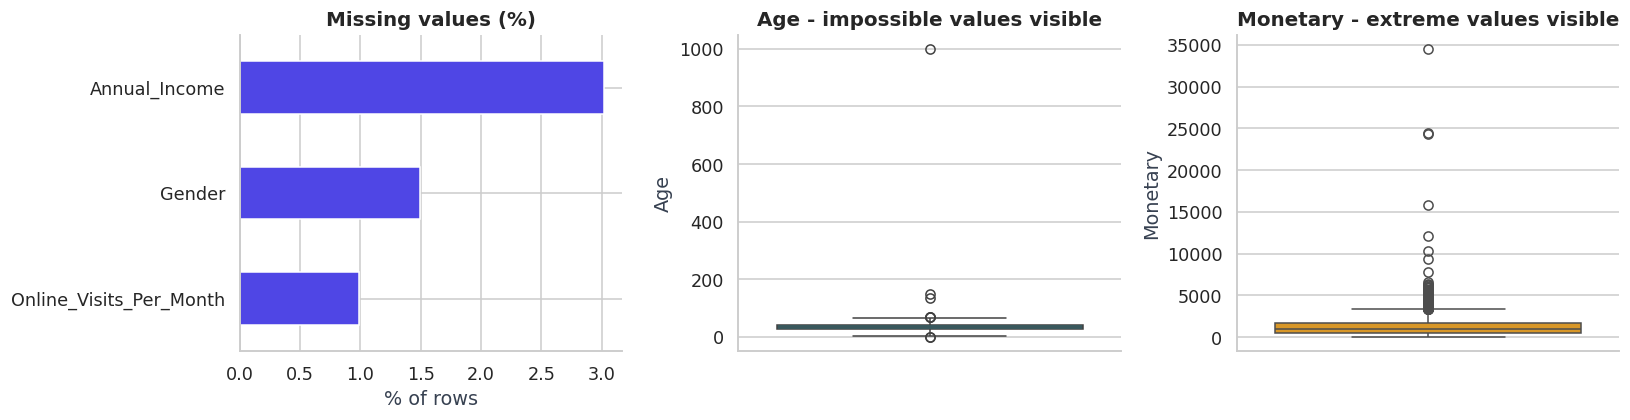

In [6]:
missing = df_raw.isna().sum()
missing = missing[missing > 0]
miss_df = pd.DataFrame({"Missing values": missing, "% of rows": (missing / len(df_raw) * 100).round(2)})

n_dup      = df_raw.duplicated().sum()
bad_age    = ((df_raw["Age"] < 18) | (df_raw["Age"] > 80)).sum()
expected   = df_raw["Frequency"] * df_raw["Avg_Order_Value"]
bad_money  = ((df_raw["Monetary"] - expected).abs() / expected > 0.25).sum()

display(miss_df)
print(f"Duplicate rows                          : {n_dup}")
print(f"Impossible ages (<18 or >80)            : {bad_age}")
print(f"Monetary inconsistent with Freq x AOV   : {bad_money}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
miss_df["% of rows"].sort_values().plot.barh(ax=ax[0], color="#4f46e5")
ax[0].set_title("Missing values (%)"); ax[0].set_xlabel("% of rows")
sns.boxplot(y=df_raw["Age"], ax=ax[1], color="#06b6d4"); ax[1].set_title("Age - impossible values visible")
sns.boxplot(y=df_raw["Monetary"], ax=ax[2], color="#f59e0b"); ax[2].set_title("Monetary - extreme values visible")
plt.tight_layout(); save_fig("01_data_quality_issues"); plt.show()

**What I found:** there are missing values in three columns, exact duplicate rows, a handful of impossible ages (e.g. 0, 150, 999) and some customers whose total spend is far higher than orders × average order value, which points to data-entry errors.

### 3.3 Cleaning (with a log of every action)
| Problem | Treatment | Why |
|---|---|---|
| Duplicate rows | Remove | A customer must be counted once |
| Impossible ages | Set to missing, then impute | Values like 0 or 999 are entry errors, not real customers |
| Missing numeric values | Median imputation | The median is not distorted by extreme values |
| Missing gender | Label `Not Specified` | Avoids inventing information |
| Inflated `Monetary` | Recompute as `Frequency × Avg_Order_Value` | Restores consistency with the other two columns |

In [7]:
df = df_raw.copy()
log = []

# 1) duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log.append(("Duplicate rows removed", before - len(df)))

# 2) impossible ages -> missing
mask = (df["Age"] < 18) | (df["Age"] > 80)
df.loc[mask, "Age"] = np.nan
log.append(("Impossible ages set to missing", int(mask.sum())))

# 3) numeric imputation (median)
for col in ["Age", "Annual_Income", "Online_Visits_Per_Month"]:
    n = int(df[col].isna().sum())
    df[col] = df[col].fillna(df[col].median())
    log.append((f"Missing '{col}' filled with median", n))

# 4) categorical imputation
n = int(df["Gender"].isna().sum())
df["Gender"] = df["Gender"].fillna("Not Specified")
log.append(("Missing 'Gender' labelled 'Not Specified'", n))

# 5) fix inconsistent Monetary
expected = df["Frequency"] * df["Avg_Order_Value"]
mask = (df["Monetary"] - expected).abs() / expected > 0.25
df.loc[mask, "Monetary"] = expected[mask].round(2)
log.append(("Inconsistent 'Monetary' recomputed", int(mask.sum())))

# ---- validation ----
assert df.isna().sum().sum() == 0, "There are still missing values!"
assert df["CustomerID"].is_unique, "Duplicate customers remain!"
assert df["Age"].between(18, 80).all()

display(pd.DataFrame(log, columns=["Cleaning step", "Rows / values affected"]))
print(f"\nClean dataset: {df.shape[0]:,} customers, {df.shape[1]} columns, 0 missing values.")

,Cleaning step,Rows / values affected
0,Duplicate rows removed,18
1,Impossible ages set to missing,6
2,Missing 'Age' filled with median,6
3,Missing 'Annual_Income' filled with median,60
4,Missing 'Online_Visits_Per_Month' filled with ...,20
5,Missing 'Gender' labelled 'Not Specified',30
6,Inconsistent 'Monetary' recomputed,8



Clean dataset: 2,000 customers, 18 columns, 0 missing values.


### 3.4 Outlier check after cleaning
I use the IQR rule to see how many extreme values remain. I **keep** them because they are genuine customers (for example a big spender), and I handle their influence later with a log transform and scaling instead of deleting real customers.

In [8]:
num_cols = ["Age", "Annual_Income", "Recency_Days", "Frequency", "Avg_Order_Value",
            "Monetary", "Discount_Usage_Pct", "Online_Visits_Per_Month"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, n_out, round(n_out / len(df) * 100, 2)))
pd.DataFrame(rows, columns=["Feature", "Outliers (IQR rule)", "% of customers"]).set_index("Feature")

,Outliers (IQR rule),% of customers
Feature,,
Age,3,0.15
Annual_Income,37,1.85
Recency_Days,201,10.05
Frequency,0,0.00
Avg_Order_Value,30,1.50
Monetary,195,9.75
Discount_Usage_Pct,0,0.00
Online_Visits_Per_Month,31,1.55


# 4. Feature Engineering
I create a few extra columns that make customers easier to describe and analyse:

- **RFM scores** (Recency, Frequency, Monetary) on a 1-5 scale. This is the classic customer-value framework in retail.
- **Age groups** and **income bands** for readable demographic comparisons.
- **Monthly spend** as a simple way to compare customers with different spending levels.

In [9]:
df["Age_Group"]   = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 100],
                           labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df["Income_Band"] = pd.qcut(df["Annual_Income"], 4, labels=["Low", "Lower-Mid", "Upper-Mid", "High"])

# RFM scores (5 = best). Recency is reversed because fewer days since purchase is better.
df["R_Score"] = pd.qcut(df["Recency_Days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
df["F_Score"] = pd.qcut(df["Frequency"].rank(method="first"),    5, labels=[1, 2, 3, 4, 5]).astype(int)
df["M_Score"] = pd.qcut(df["Monetary"].rank(method="first"),     5, labels=[1, 2, 3, 4, 5]).astype(int)
df["RFM_Total"]     = df[["R_Score", "F_Score", "M_Score"]].sum(axis=1)
df["Monthly_Spend"] = (df["Monetary"] / 12).round(2)

df[["CustomerID", "Age_Group", "Income_Band", "R_Score", "F_Score", "M_Score", "RFM_Total", "Monthly_Spend"]].head()

,CustomerID,Age_Group,Income_Band,R_Score,F_Score,M_Score,RFM_Total,Monthly_Spend
0,CUST10000,36-45,Upper-Mid,5,3,4,12,146.40
1,CUST10001,18-25,Low,2,2,2,6,47.71
2,CUST10002,26-35,Lower-Mid,1,1,1,3,22.92
3,CUST10003,26-35,Lower-Mid,5,4,3,12,66.58
4,CUST10004,36-45,Lower-Mid,1,2,1,4,20.97


# 5. Exploratory Data Analysis
Before clustering, I want to understand **who** the customers are, **how** they buy and **what** they prefer. This also tells me what structure the algorithm might find.

### 5.1 Who are our customers? (Demographics)

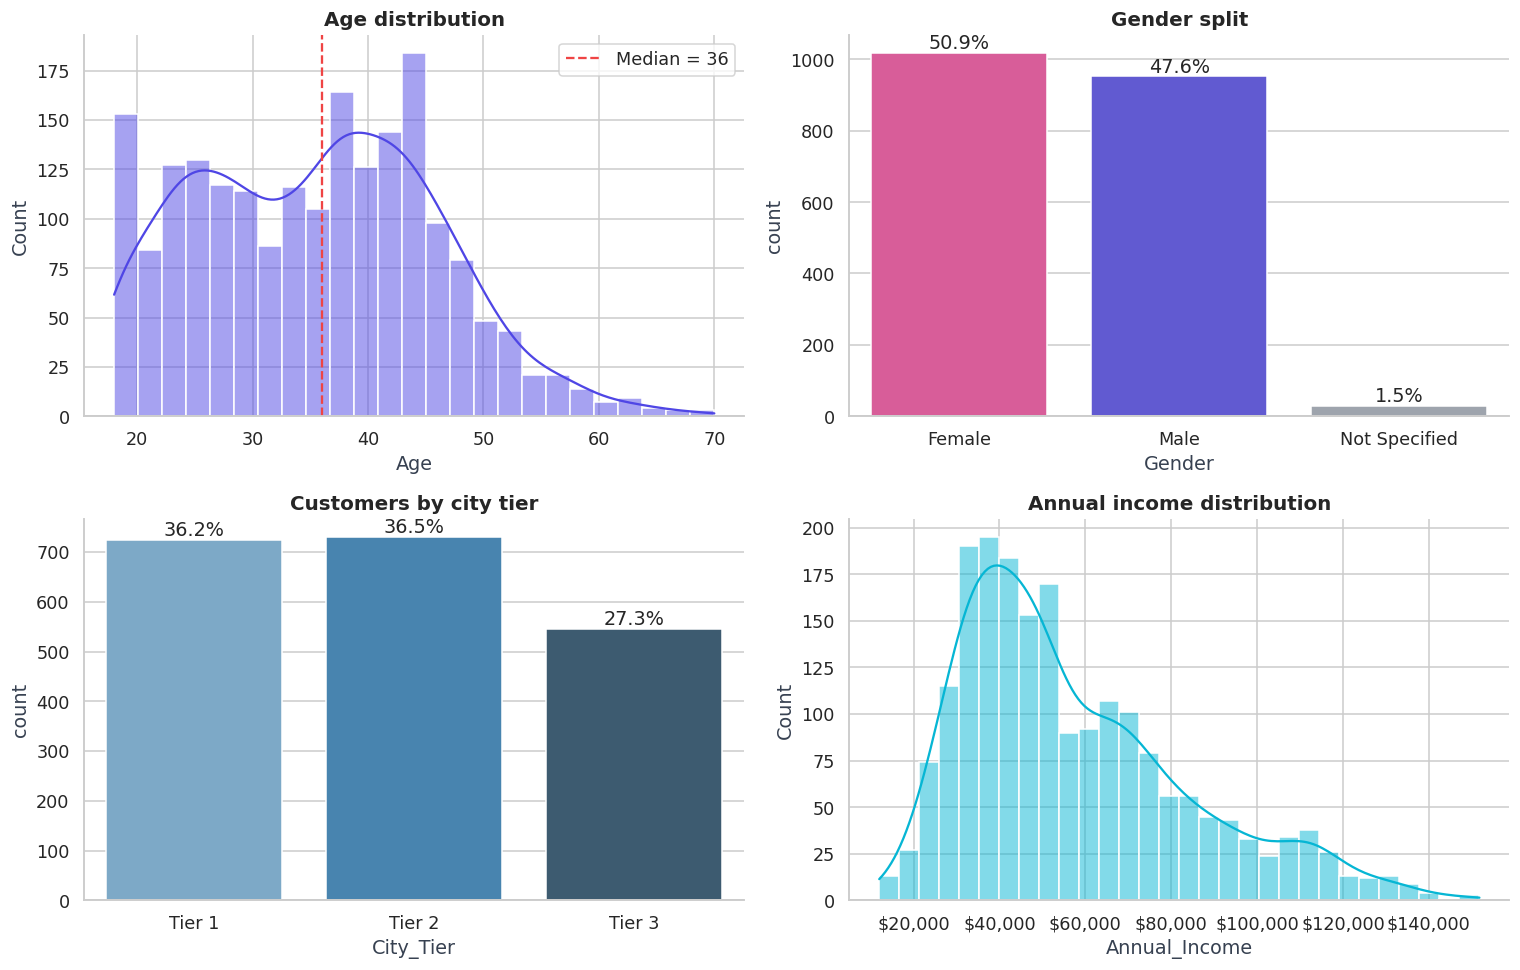

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df["Age"], bins=25, kde=True, color="#4f46e5", ax=ax[0, 0])
ax[0, 0].set_title("Age distribution"); ax[0, 0].axvline(df["Age"].median(), color="#ef4444", ls="--", label=f"Median = {df['Age'].median():.0f}"); ax[0, 0].legend()

order = df["Gender"].value_counts().index
sns.countplot(x="Gender", data=df, order=order, palette=["#ec4899", "#4f46e5", "#9ca3af"][:len(order)], ax=ax[0, 1])
ax[0, 1].set_title("Gender split")
for p in ax[0, 1].patches: ax[0, 1].annotate(f"{p.get_height()/len(df)*100:.1f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

sns.countplot(x="City_Tier", data=df, order=["Tier 1", "Tier 2", "Tier 3"], palette="Blues_d", ax=ax[1, 0])
ax[1, 0].set_title("Customers by city tier")
for p in ax[1, 0].patches: ax[1, 0].annotate(f"{p.get_height()/len(df)*100:.1f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

sns.histplot(df["Annual_Income"], bins=30, kde=True, color="#06b6d4", ax=ax[1, 1])
ax[1, 1].set_title("Annual income distribution"); ax[1, 1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout(); save_fig("02_demographics"); plt.show()

### 5.2 How do they buy? (Purchase patterns)

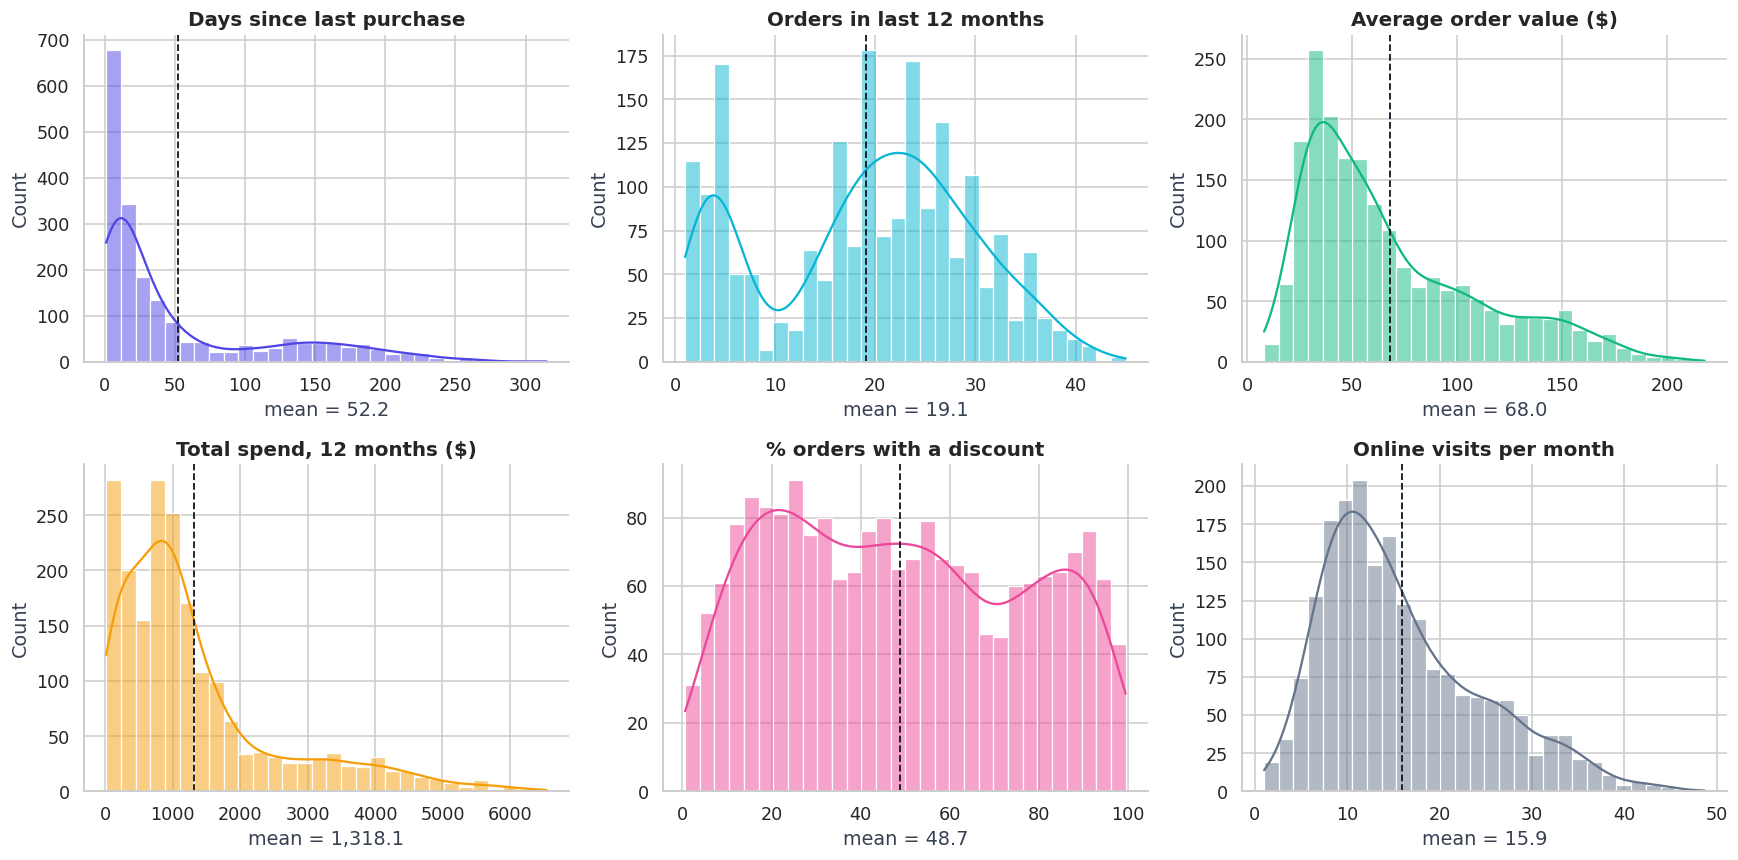

In [11]:
metrics = [("Recency_Days", "Days since last purchase", "#4f46e5"), ("Frequency", "Orders in last 12 months", "#06b6d4"),
           ("Avg_Order_Value", "Average order value ($)", "#10b981"), ("Monetary", "Total spend, 12 months ($)", "#f59e0b"),
           ("Discount_Usage_Pct", "% orders with a discount", "#ec4899"), ("Online_Visits_Per_Month", "Online visits per month", "#64748b")]
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, (col, title, colr) in zip(ax.ravel(), metrics):
    sns.histplot(df[col], bins=30, kde=True, color=colr, ax=a)
    a.axvline(df[col].mean(), color="#111827", ls="--", lw=1.2)
    a.set_title(title); a.set_xlabel(f"mean = {df[col].mean():,.1f}")
plt.tight_layout(); save_fig("03_purchase_patterns"); plt.show()

**Observation:** several behaviour variables are *not* a single bell curve (frequency and spend have more than one peak, and recency is strongly right-skewed). This is the first sign that different customer groups exist in the data, which is exactly what clustering will separate.

### 5.3 What do they prefer? (Category & channel)

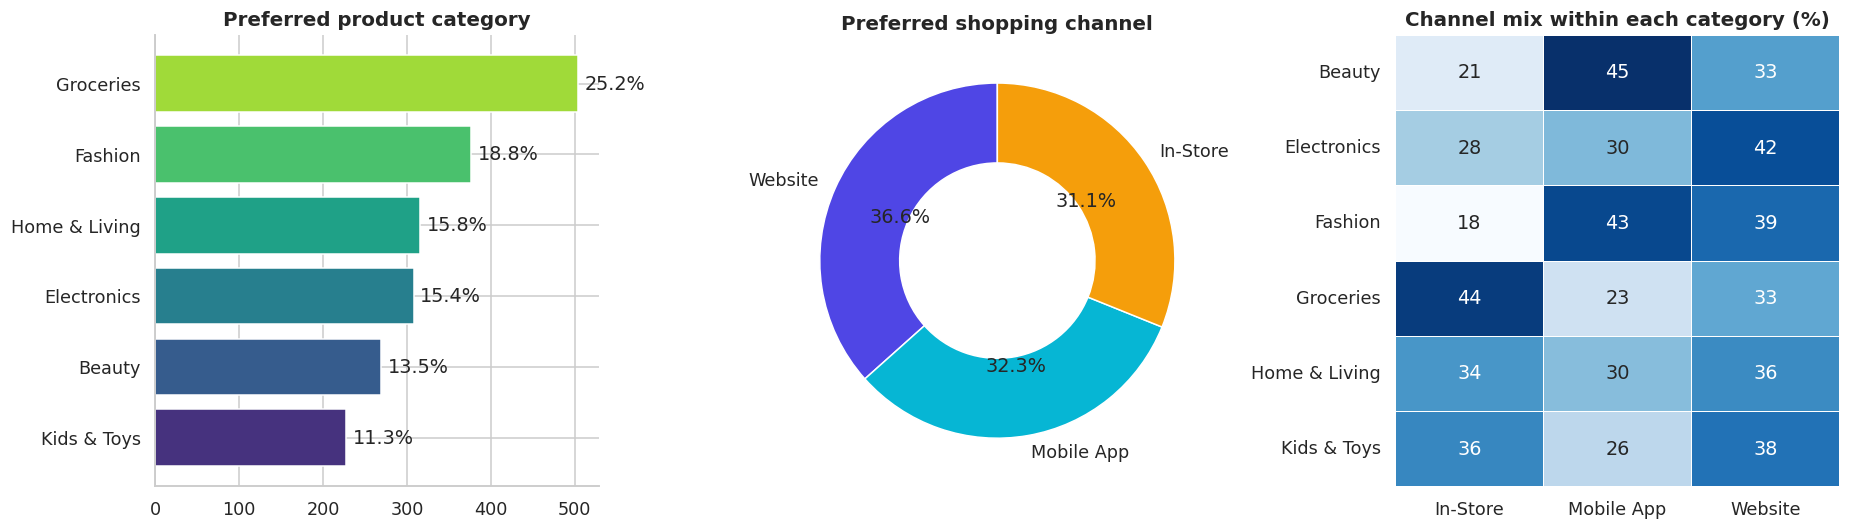

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

cat = df["Preferred_Category"].value_counts().sort_values()
ax[0].barh(cat.index, cat.values, color=sns.color_palette("viridis", len(cat)))
ax[0].set_title("Preferred product category")
for i, v in enumerate(cat.values): ax[0].text(v + 8, i, f"{v/len(df)*100:.1f}%", va="center")

ch = df["Preferred_Channel"].value_counts()
ax[1].pie(ch.values, labels=ch.index, autopct="%1.1f%%", startangle=90, colors=["#4f46e5", "#06b6d4", "#f59e0b"],
          wedgeprops=dict(width=.45, edgecolor="white"))
ax[1].set_title("Preferred shopping channel")

ct = pd.crosstab(df["Preferred_Category"], df["Preferred_Channel"], normalize="index") * 100
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax[2], linewidths=.5)
ax[2].set_title("Channel mix within each category (%)"); ax[2].set_xlabel(""); ax[2].set_ylabel("")

plt.tight_layout(); save_fig("04_preferences"); plt.show()

### 5.4 How are the variables related? (Correlation)
Highly correlated variables carry the same information twice and would give that information extra weight in K-Means, so I check this before choosing the clustering features.

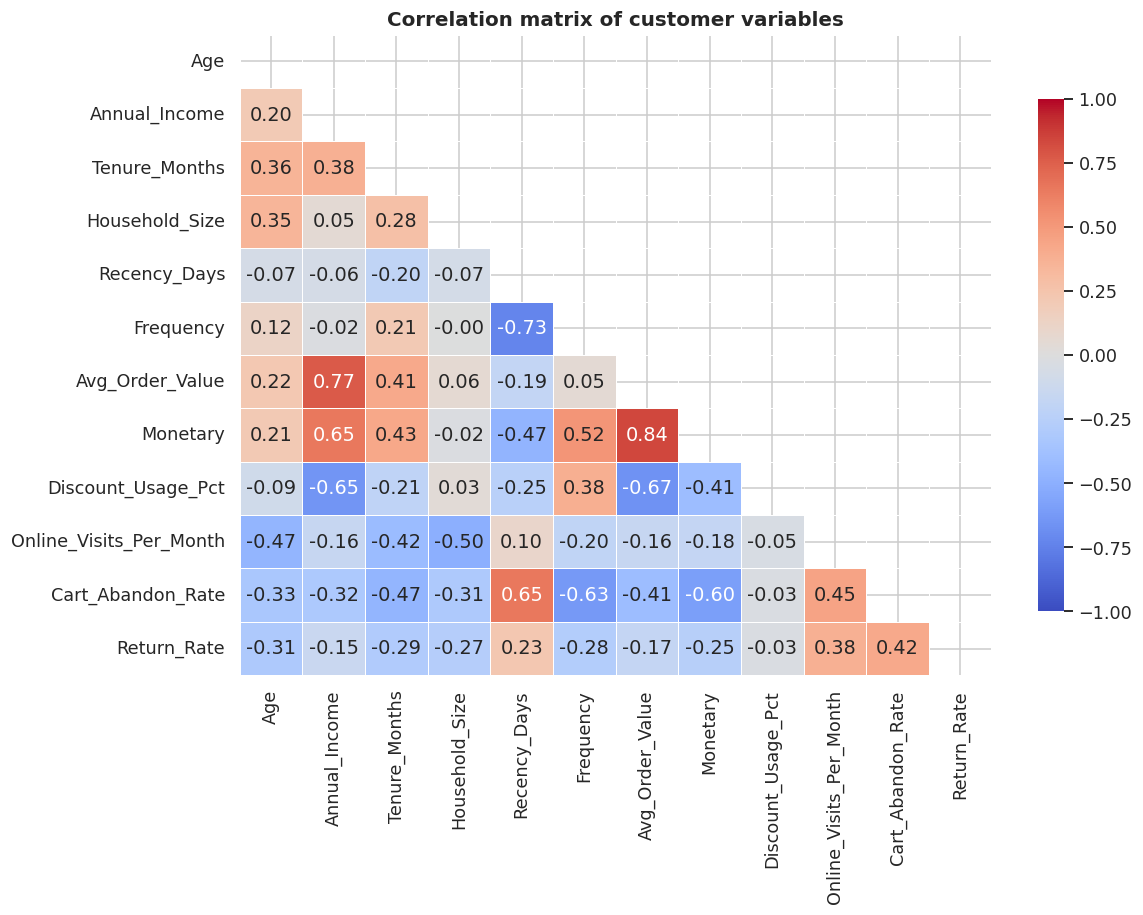

Strongest relationships:


,Variable A,Variable B,r
0,Monetary,Avg_Order_Value,0.84
1,Avg_Order_Value,Annual_Income,0.77
2,Frequency,Recency_Days,-0.73
3,Discount_Usage_Pct,Avg_Order_Value,-0.67
4,Monetary,Annual_Income,0.65
5,Discount_Usage_Pct,Annual_Income,-0.65


In [13]:
corr_cols = ["Age", "Annual_Income", "Tenure_Months", "Household_Size", "Recency_Days", "Frequency", "Avg_Order_Value",
             "Monetary", "Discount_Usage_Pct", "Online_Visits_Per_Month", "Cart_Abandon_Rate", "Return_Rate"]
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation matrix of customer variables")
plt.tight_layout(); save_fig("05_correlation"); plt.show()

pairs = (corr.where(~mask).stack().dropna().rename("r").reset_index()
         .rename(columns={"level_0": "Variable A", "level_1": "Variable B"}))
pairs["abs_r"] = pairs["r"].abs()
print("Strongest relationships:")
display(pairs.sort_values("abs_r", ascending=False).head(6).drop(columns="abs_r").reset_index(drop=True))

**What the correlations tell me**
- `Monetary` is strongly linked to `Avg_Order_Value` (r = 0.84), which confirms that total spend is largely a product of order size and order count, so I will leave it out of the model and use it for profiling.
- `Avg_Order_Value` rises with `Annual_Income` (r = 0.77): higher earners buy bigger baskets.
- `Frequency` and `Recency_Days` move in opposite directions (r = -0.73): customers who buy often also bought recently, while infrequent buyers have gone quiet.
- `Discount_Usage_Pct` is negatively related to order value and income, so discount-driven customers tend to be lower-income, smaller-basket shoppers.
- No pair among the clustering features exceeds |r| = 0.8, so no feature is redundant (checked again in Section 6).

# 6. Pre-processing for Clustering

### 6.1 Choosing the clustering features
- **Demographic + behavioural numeric variables** go into the model.
- `Monetary` is **excluded** because it equals `Frequency × Avg_Order_Value`. Keeping all three would count spending value twice. I still use it later to profile the segments.
- **Categorical preferences** (category, channel, gender, city tier) are **not** fed to K-Means, because it uses Euclidean distance and dummy variables distort it. I use them afterwards to *describe* each segment, which keeps the clusters clean and the interpretation rich.

In [14]:
FEATURES = ["Age", "Annual_Income", "Tenure_Months", "Household_Size",
            "Recency_Days", "Frequency", "Avg_Order_Value",
            "Discount_Usage_Pct", "Online_Visits_Per_Month", "Cart_Abandon_Rate", "Return_Rate"]

# multicollinearity check among the chosen features
c = df[FEATURES].corr().abs().where(~np.triu(np.ones((len(FEATURES),) * 2, dtype=bool)))
high = c.stack().dropna()[lambda s: s > 0.8]
print("Feature pairs with |r| > 0.8:", "none - good, no redundant features" if high.empty else high.to_dict())

skew = df[FEATURES].skew().sort_values(ascending=False).to_frame("Skewness")
display(skew)

Feature pairs with |r| > 0.8: none - good, no redundant features


,Skewness
Recency_Days,1.45
Avg_Order_Value,1.05
Return_Rate,0.98
Annual_Income,0.94
Online_Visits_Per_Month,0.88
Household_Size,0.65
Cart_Abandon_Rate,0.35
Tenure_Months,0.32
Age,0.24
Discount_Usage_Pct,0.15


### 6.2 Fix skewed variables and scale
- Variables with **|skewness| > 1** get a `log1p` transform so a few extreme values do not dominate the distances.
- **StandardScaler** (mean 0, standard deviation 1) puts all features on the same scale. Without it, `Annual_Income` (tens of thousands) would swamp `Return_Rate` (tens).

Log-transformed features: ['Recency_Days', 'Avg_Order_Value']
Model matrix: 2,000 customers x 11 features | mean ~ -0.00, std ~ 1.00


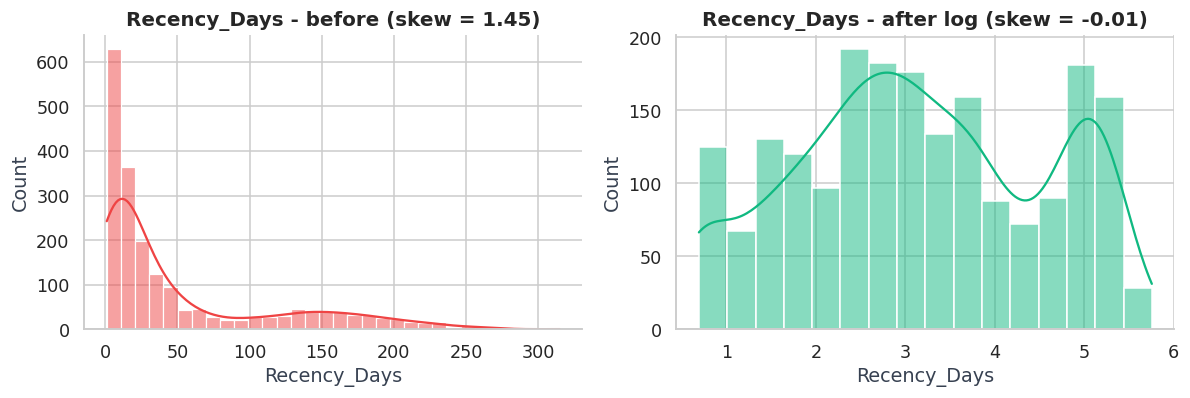

In [15]:
skewed = skew[skew["Skewness"].abs() > 1].index.tolist()
print("Log-transformed features:", skewed)

X_df = df[FEATURES].copy()
for col in skewed:
    X_df[col] = np.log1p(X_df[col])

scaler = StandardScaler()
X = scaler.fit_transform(X_df)
print(f"Model matrix: {X.shape[0]:,} customers x {X.shape[1]} features | mean ~ {X.mean():.2f}, std ~ {X.std():.2f}")

# visual proof of the transform on the most skewed variable
col = skew.index[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df[col], kde=True, color="#ef4444", ax=ax[0]); ax[0].set_title(f"{col} - before (skew = {df[col].skew():.2f})")
sns.histplot(X_df[col], kde=True, color="#10b981", ax=ax[1]); ax[1].set_title(f"{col} - after log (skew = {X_df[col].skew():.2f})")
plt.tight_layout(); save_fig("06_skew_fix"); plt.show()

# 7. Choosing the Number of Segments
K-Means needs the number of clusters (**K**) in advance. Rather than guessing, I test K = 2 to 10 using four different measures and look for agreement:

| Metric | What it tells me | Best value |
|---|---|---|
| **Inertia (elbow)** | How compact the clusters are | Point where improvement flattens |
| **Silhouette score** | How well each customer fits its own cluster vs the next closest | Higher |
| **Calinski-Harabasz** | Ratio of between-cluster to within-cluster spread | Higher |
| **Davies-Bouldin** | Average similarity between clusters | Lower |

In [16]:
def find_elbow(ks, inertias):
    """Elbow = the point furthest from the straight line joining the first and last points."""
    x = np.array(ks, float); y = np.array(inertias, float)
    x = (x - x.min()) / (x.max() - x.min()); y = (y - y.min()) / (y.max() - y.min())
    dx, dy = x[-1] - x[0], y[-1] - y[0]
    dist = np.abs(dx * (y - y[0]) - dy * (x - x[0])) / np.hypot(dx, dy)
    return int(ks[int(dist.argmax())])

ks = list(range(2, 11))
res = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    res.append(dict(K=k, Inertia=km.inertia_, Silhouette=silhouette_score(X, km.labels_),
                    Calinski_Harabasz=calinski_harabasz_score(X, km.labels_),
                    Davies_Bouldin=davies_bouldin_score(X, km.labels_)))
k_df = pd.DataFrame(res).set_index("K")

elbow_k = find_elbow(ks, k_df["Inertia"].values)
print(f"Elbow method suggests      : K = {elbow_k}")
print(f"Best silhouette            : K = {k_df['Silhouette'].idxmax()}")
print(f"Best Calinski-Harabasz     : K = {k_df['Calinski_Harabasz'].idxmax()}")
print(f"Best (lowest) Davies-Bouldin: K = {k_df['Davies_Bouldin'].idxmin()}")
k_df

Elbow method suggests      : K = 5
Best silhouette            : K = 4
Best Calinski-Harabasz     : K = 4
Best (lowest) Davies-Bouldin: K = 3


,Inertia,Silhouette,Calinski_Harabasz,Davies_Bouldin
K,,,,
2,15932.01,0.27,760.97,1.57
3,11992.38,0.31,833.25,1.21
4,9747.39,0.32,836.33,1.21
5,8358.95,0.32,813.92,1.24
6,7996.30,0.29,698.41,1.61
7,7699.72,0.24,616.92,1.86
8,7429.87,0.24,558.05,1.82
9,7217.64,0.20,509.72,1.98
10,7068.65,0.16,467.06,2.16


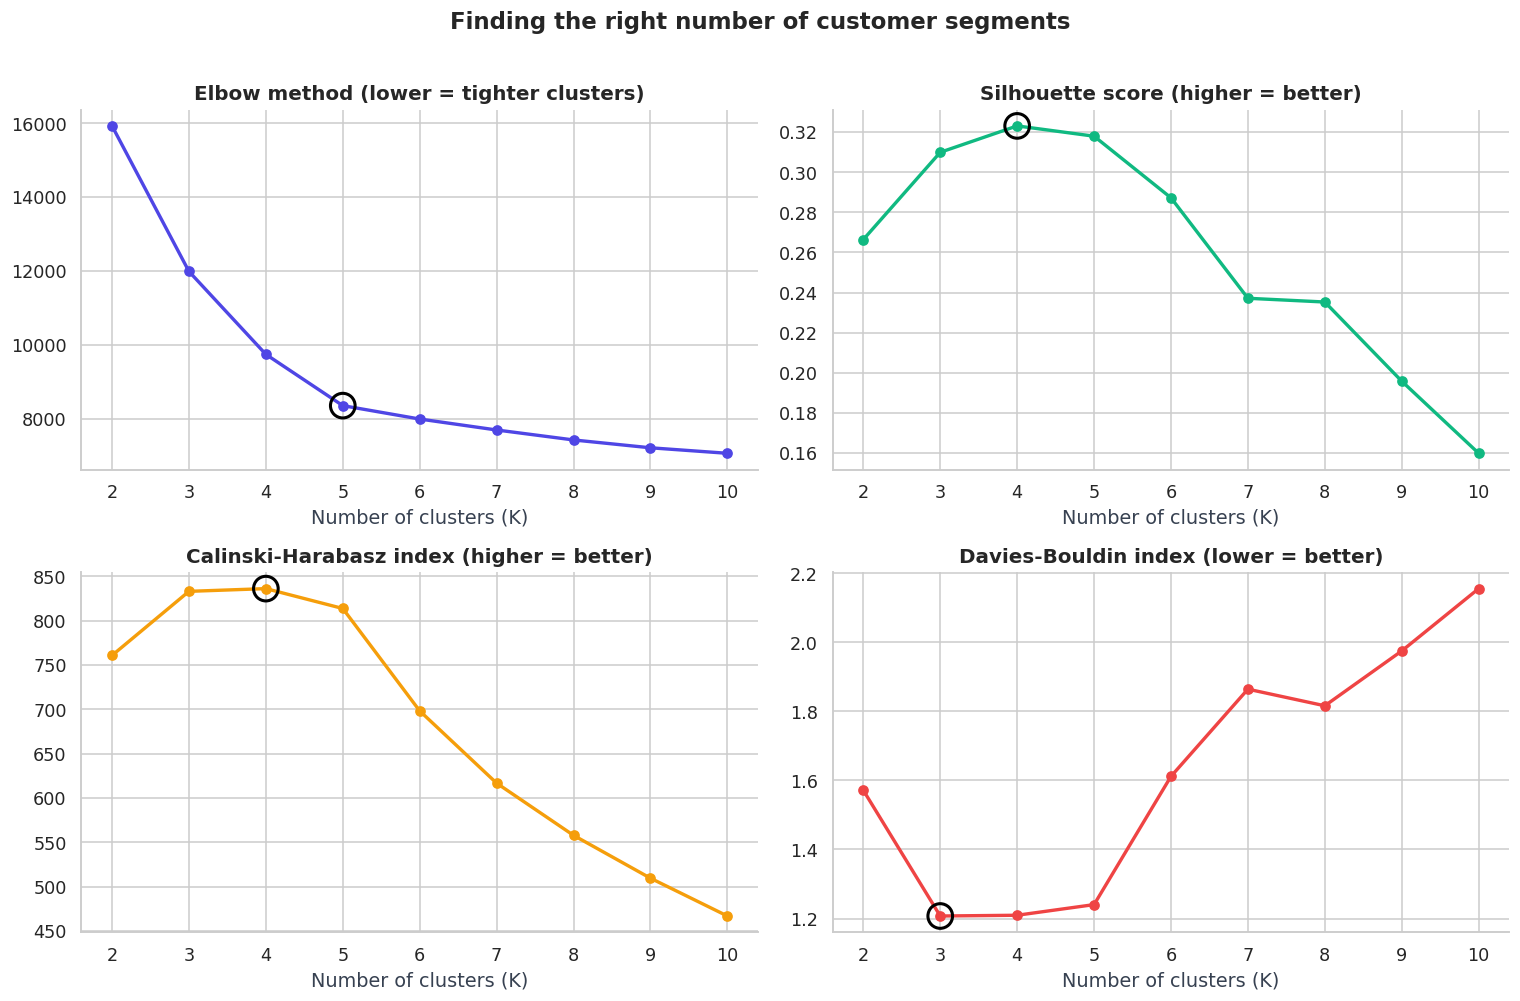

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
specs = [("Inertia", "Elbow method (lower = tighter clusters)", "#4f46e5"),
         ("Silhouette", "Silhouette score (higher = better)", "#10b981"),
         ("Calinski_Harabasz", "Calinski-Harabasz index (higher = better)", "#f59e0b"),
         ("Davies_Bouldin", "Davies-Bouldin index (lower = better)", "#ef4444")]
for a, (m, t, c) in zip(ax.ravel(), specs):
    a.plot(k_df.index, k_df[m], marker="o", lw=2.2, color=c)
    best = k_df[m].idxmin() if m in ("Davies_Bouldin",) else (elbow_k if m == "Inertia" else k_df[m].idxmax())
    a.scatter(best, k_df.loc[best, m], s=260, facecolors="none", edgecolors="black", lw=2, zorder=5)
    a.set_title(t); a.set_xlabel("Number of clusters (K)"); a.set_xticks(ks)
plt.suptitle("Finding the right number of customer segments", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); save_fig("07_choose_k"); plt.show()

### 7.1 My decision: K = 5
Reading the four charts together, the metrics agree on a **small range of 3 to 5 clusters**. K = 4 and K = 5 are essentially tied on the silhouette score (the difference is below 0.01), so the maths alone does not settle it. I therefore checked what changes when I go from 4 to 5 segments:

In [18]:
km4 = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(X)
km5 = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X)

# which K=4 cluster gets split when I move to K=5?
tab = pd.crosstab(pd.Series(km4.labels_, name="K=4 cluster"), pd.Series(km5.labels_, name="K=5 cluster"))
display(tab)

split_from = tab.apply(lambda r: (r > 0.2 * r.sum()).sum(), axis=1).idxmax()
parts = tab.loc[split_from][tab.loc[split_from] > 0.2 * tab.loc[split_from].sum()].index.tolist()
a, b = (df.loc[(km4.labels_ == split_from) & (km5.labels_ == p)] for p in parts[:2])
cmp = pd.DataFrame({f"Sub-group A (n={len(a)})": a[["Annual_Income", "Avg_Order_Value", "Household_Size", "Online_Visits_Per_Month", "Discount_Usage_Pct"]].mean(),
                    f"Sub-group B (n={len(b)})": b[["Annual_Income", "Avg_Order_Value", "Household_Size", "Online_Visits_Per_Month", "Discount_Usage_Pct"]].mean()})
cmp["Difference (%)"] = ((cmp.iloc[:, 0] - cmp.iloc[:, 1]) / cmp.iloc[:, 1] * 100).round(0)
print(f"Moving from K=4 to K=5 splits K=4 cluster {split_from} into two groups that behave very differently:")
display(cmp)

K=5 cluster,0,1,2,3,4
K=4 cluster,,,,,
0,420,0,0,0,0
1,0,323,0,0,316
2,0,0,459,0,0
3,0,1,0,481,0


Moving from K=4 to K=5 splits K=4 cluster 1 into two groups that behave very differently:


,Sub-group A (n=323),Sub-group B (n=316),Difference (%)
Annual_Income,69350.15,101789.56,-32.0
Avg_Order_Value,94.26,142.89,-34.0
Household_Size,5.01,1.92,160.0
Online_Visits_Per_Month,8.14,14.10,-42.0
Discount_Usage_Pct,38.88,14.02,177.0


**Conclusion:** the extra cluster at K = 5 is **not noise**. It splits one large "high-value, regular buyer" group into two sets of customers with clearly different income, basket size and household profile, which need different marketing. Since the statistical scores are tied and the 5th cluster adds real business meaning, I choose **K = 5**.

# 8. Building & Validating the Model

### 8.1 Final K-Means model

In [19]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X)
df["Cluster"] = kmeans.labels_

sil = silhouette_score(X, kmeans.labels_)
print(f"K-Means with K={K}")
print(f"  Silhouette score       : {sil:.3f}")
print(f"  Calinski-Harabasz      : {calinski_harabasz_score(X, kmeans.labels_):,.0f}")
print(f"  Davies-Bouldin         : {davies_bouldin_score(X, kmeans.labels_):.3f}")
print("\nCluster sizes:")
display(df["Cluster"].value_counts().sort_index().to_frame("Customers").assign(Share=lambda d: (d["Customers"] / len(df) * 100).round(1).astype(str) + "%"))

K-Means with K=5
  Silhouette score       : 0.318
  Calinski-Harabasz      : 814
  Davies-Bouldin         : 1.240

Cluster sizes:


,Customers,Share
Cluster,,
0,420,21.0%
1,324,16.2%
2,459,23.0%
3,481,24.0%
4,316,15.8%


### 8.2 Silhouette plot per cluster
Each bar is a customer. Bars that extend to the right fit their cluster well. A cluster whose bars are mostly negative would signal poor assignment.

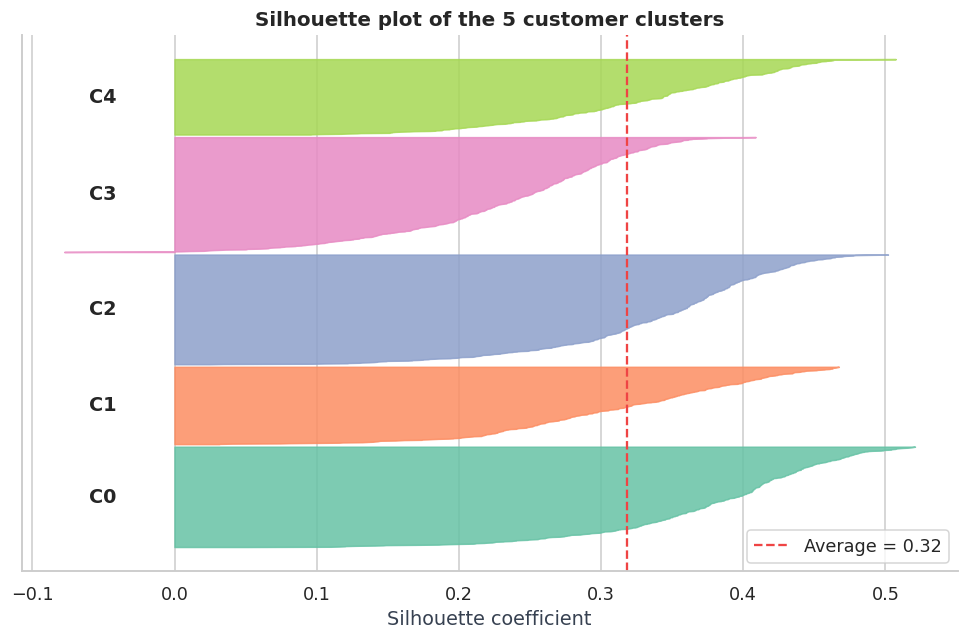

Customers with a negative silhouette (possibly mis-assigned): 3 (0.1%)


In [20]:
sample_sil = silhouette_samples(X, kmeans.labels_)
fig, ax = plt.subplots(figsize=(9, 6))
y_lower = 10
colors = sns.color_palette("Set2", K)
for i in range(K):
    vals = np.sort(sample_sil[kmeans.labels_ == i])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=colors[i], alpha=.85)
    ax.text(-0.06, y_lower + len(vals) / 2, f"C{i}", va="center", fontweight="bold")
    y_lower = y_upper + 10
ax.axvline(sil, color="#ef4444", ls="--", label=f"Average = {sil:.2f}")
ax.set_title("Silhouette plot of the 5 customer clusters"); ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([]); ax.legend()
plt.tight_layout(); save_fig("08_silhouette_plot"); plt.show()

print(f"Customers with a negative silhouette (possibly mis-assigned): {(sample_sil < 0).sum()} ({(sample_sil < 0).mean() * 100:.1f}%)")

### 8.3 Do other algorithms agree? (Cross-validation of the result)
A good segmentation should not depend on one specific algorithm. I compare K-Means with **Hierarchical (Ward) clustering** and a **Gaussian Mixture Model**. The **Adjusted Rand Index (ARI)** measures how similar two groupings are (1 = identical, 0 = random).

,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI_vs_KMeans
K-Means,0.32,813.92,1.24,1.00
Hierarchical (Ward),0.32,810.12,1.24,0.99
Gaussian Mixture,0.32,813.28,1.24,1.00


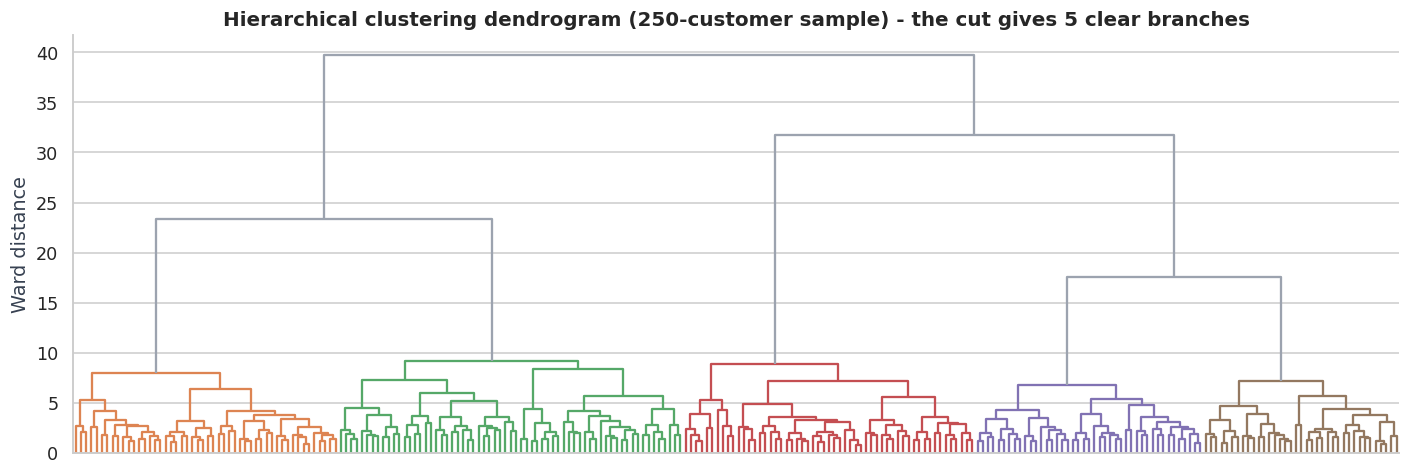

In [21]:
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=RANDOM_STATE).fit(X)
gmm_labels = gmm.predict(X)

models = {"K-Means": kmeans.labels_, "Hierarchical (Ward)": agg.labels_, "Gaussian Mixture": gmm_labels}
cmp = pd.DataFrame({name: dict(Silhouette=silhouette_score(X, l), Calinski_Harabasz=calinski_harabasz_score(X, l),
                               Davies_Bouldin=davies_bouldin_score(X, l),
                               ARI_vs_KMeans=adjusted_rand_score(kmeans.labels_, l)) for name, l in models.items()}).T
display(cmp)

# Dendrogram on a random sample of 250 customers (a full dendrogram of ~2,000 is unreadable)
idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 250, replace=False)
Z = linkage(X[idx], method="ward")
plt.figure(figsize=(13, 4.5))
dendrogram(Z, no_labels=True, color_threshold=Z[-(K - 1), 2], above_threshold_color="#9ca3af")
plt.title("Hierarchical clustering dendrogram (250-customer sample) - the cut gives 5 clear branches")
plt.ylabel("Ward distance"); plt.tight_layout(); save_fig("09_dendrogram"); plt.show()

### 8.4 Is the solution stable? (Bootstrap test)
I re-fit K-Means 30 times on random resamples of the customers and check how similar every new grouping is to my final one. If the segments are real, they should reappear every time.

Stability (ARI vs final model): mean = 0.999, min = 0.997, max = 1.000


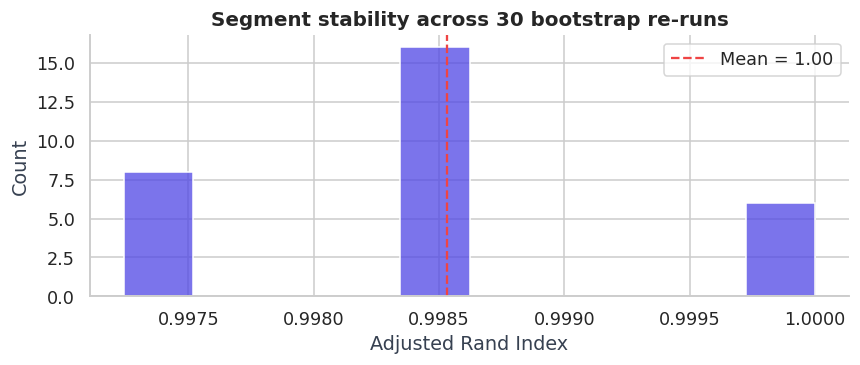

In [22]:
rng = np.random.RandomState(RANDOM_STATE)
aris = []
for s in range(30):
    idx = rng.choice(len(X), len(X), replace=True)                       # bootstrap resample
    km_b = KMeans(n_clusters=K, n_init=10, random_state=s).fit(X[idx])
    aris.append(adjusted_rand_score(kmeans.labels_, km_b.predict(X)))

print(f"Stability (ARI vs final model): mean = {np.mean(aris):.3f}, min = {np.min(aris):.3f}, max = {np.max(aris):.3f}")
plt.figure(figsize=(8, 3.5))
sns.histplot(aris, bins=10, color="#4f46e5"); plt.axvline(np.mean(aris), color="#ef4444", ls="--", label=f"Mean = {np.mean(aris):.2f}")
plt.title("Segment stability across 30 bootstrap re-runs"); plt.xlabel("Adjusted Rand Index"); plt.legend()
plt.tight_layout(); save_fig("10_stability"); plt.show()

**Validation summary:** the three algorithms produce very similar groupings (high ARI) and the segments reappear almost identically in the resampling test (stability close to 1). So the segmentation reflects real structure in the customers and not a random outcome of one run.

# 9. Visualising the Segments (PCA)
My model works in 11 dimensions, which cannot be drawn. **PCA** compresses them into two components that keep as much of the variation as possible, so I can see the clusters on a map.

PC1 explains 32.5% and PC2 explains 22.1% of the variance (total 54.6%)


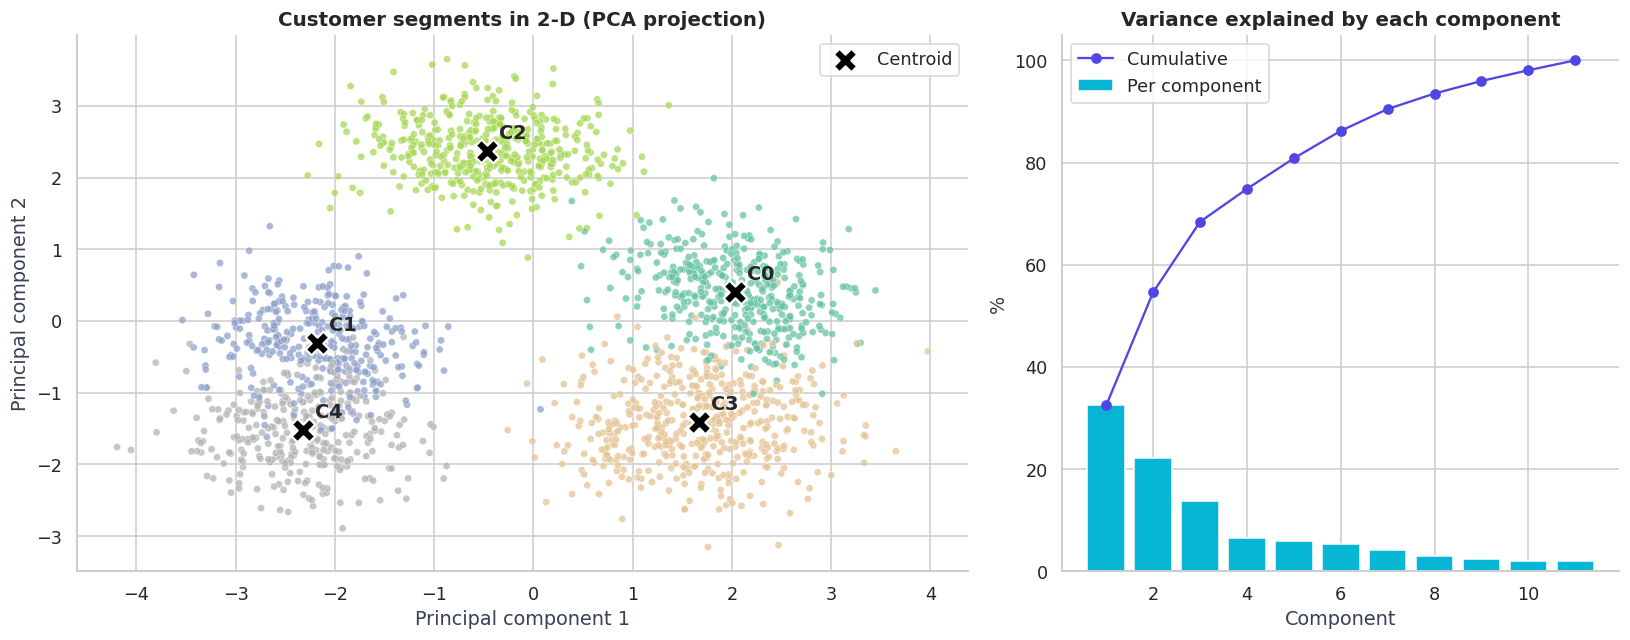

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pc = pca.fit_transform(X)
df["PC1"], df["PC2"] = pc[:, 0], pc[:, 1]
centers_pc = pca.transform(kmeans.cluster_centers_)
print(f"PC1 explains {pca.explained_variance_ratio_[0]*100:.1f}% and PC2 explains {pca.explained_variance_ratio_[1]*100:.1f}% "
      f"of the variance (total {pca.explained_variance_ratio_.sum()*100:.1f}%)")

full_pca = PCA().fit(X)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.6, 1]})
sc = ax[0].scatter(df["PC1"], df["PC2"], c=df["Cluster"], cmap="Set2", s=22, alpha=.75, edgecolor="white", linewidth=.3)
ax[0].scatter(centers_pc[:, 0], centers_pc[:, 1], c="black", marker="X", s=240, edgecolor="white", linewidth=1.5, label="Centroid", zorder=5)
for i, (x, y) in enumerate(centers_pc): ax[0].annotate(f"C{i}", (x, y), xytext=(8, 8), textcoords="offset points", fontweight="bold")
ax[0].set_title("Customer segments in 2-D (PCA projection)"); ax[0].set_xlabel("Principal component 1"); ax[0].set_ylabel("Principal component 2"); ax[0].legend()

cum = np.cumsum(full_pca.explained_variance_ratio_) * 100
ax[1].bar(range(1, len(cum) + 1), full_pca.explained_variance_ratio_ * 100, color="#06b6d4", label="Per component")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o", color="#4f46e5", label="Cumulative")
ax[1].set_title("Variance explained by each component"); ax[1].set_xlabel("Component"); ax[1].set_ylabel("%"); ax[1].legend()
plt.tight_layout(); save_fig("11_pca_clusters"); plt.show()

**What drives the two axes?** The loadings show which original variables contribute most to each component. This lets me read the map instead of just looking at coloured dots.

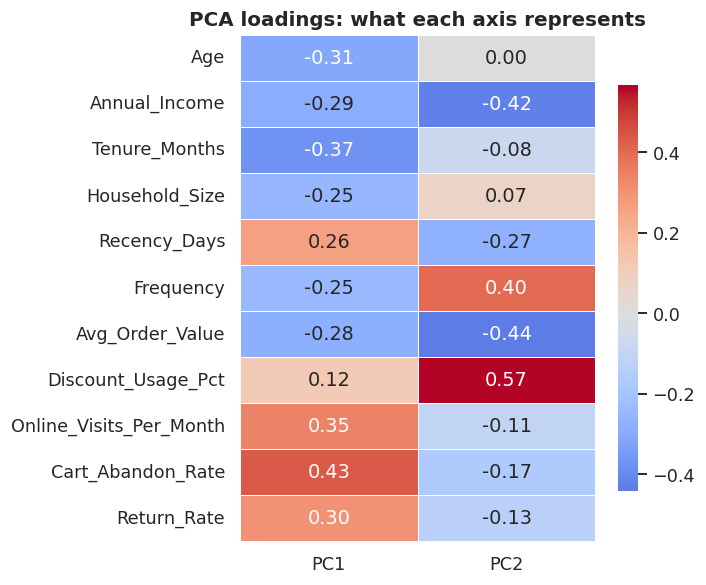

In [24]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("PCA loadings: what each axis represents")
plt.tight_layout(); save_fig("12_pca_loadings"); plt.show()

# 10. Segment Profiling & Key Characteristics
The algorithm only gives numeric labels (0-4). To make them useful for the business, I describe what each cluster *looks like* and give it a meaningful name.

### 10.1 Naming the segments
Cluster numbers are arbitrary and can change between runs, so I assign names using **rules based on the segment averages** (not by hard-coding cluster numbers). That keeps the notebook reproducible.

In [25]:
prof_raw = df.groupby("Cluster").agg(Monetary=("Monetary", "mean"), Recency=("Recency_Days", "mean"),
                                     Discount=("Discount_Usage_Pct", "mean"), Age=("Age", "mean"))
remaining, names = list(prof_raw.index), {}

def pick(label, series, largest=True):
    cid = series.loc[remaining].idxmax() if largest else series.loc[remaining].idxmin()
    names[cid] = label; remaining.remove(cid)

pick("Premium Loyalists",   prof_raw["Monetary"])                  # highest total spend
pick("Dormant Browsers",    prof_raw["Recency"])                   # longest time since last purchase
pick("Bargain Hunters",     prof_raw["Discount"])                  # most discount-driven
pick("Young Trendsetters",  prof_raw["Age"], largest=False)        # youngest of the rest
names[remaining[0]] = "Family Planners"                            # the remaining group

SEG_ORDER  = ["Premium Loyalists", "Family Planners", "Young Trendsetters", "Bargain Hunters", "Dormant Browsers"]
SEG_COLORS = {"Premium Loyalists": "#4f46e5", "Family Planners": "#10b981", "Young Trendsetters": "#ec4899",
              "Bargain Hunters": "#f59e0b", "Dormant Browsers": "#64748b"}

df["Segment"] = pd.Categorical(df["Cluster"].map(names), categories=SEG_ORDER, ordered=True)
rule_tbl = pd.DataFrame({"Cluster #": list(names.keys()), "Segment name": list(names.values())}).sort_values("Cluster #").set_index("Cluster #")
display(rule_tbl)
display(df["Segment"].value_counts().reindex(SEG_ORDER).to_frame("Customers"))

,Segment name
Cluster #,
0,Young Trendsetters
1,Family Planners
2,Bargain Hunters
3,Dormant Browsers
4,Premium Loyalists


,Customers
Segment,
Premium Loyalists,316
Family Planners,324
Young Trendsetters,420
Bargain Hunters,459
Dormant Browsers,481


### 10.2 The segment map
The same PCA picture as before, now with the final segment names.

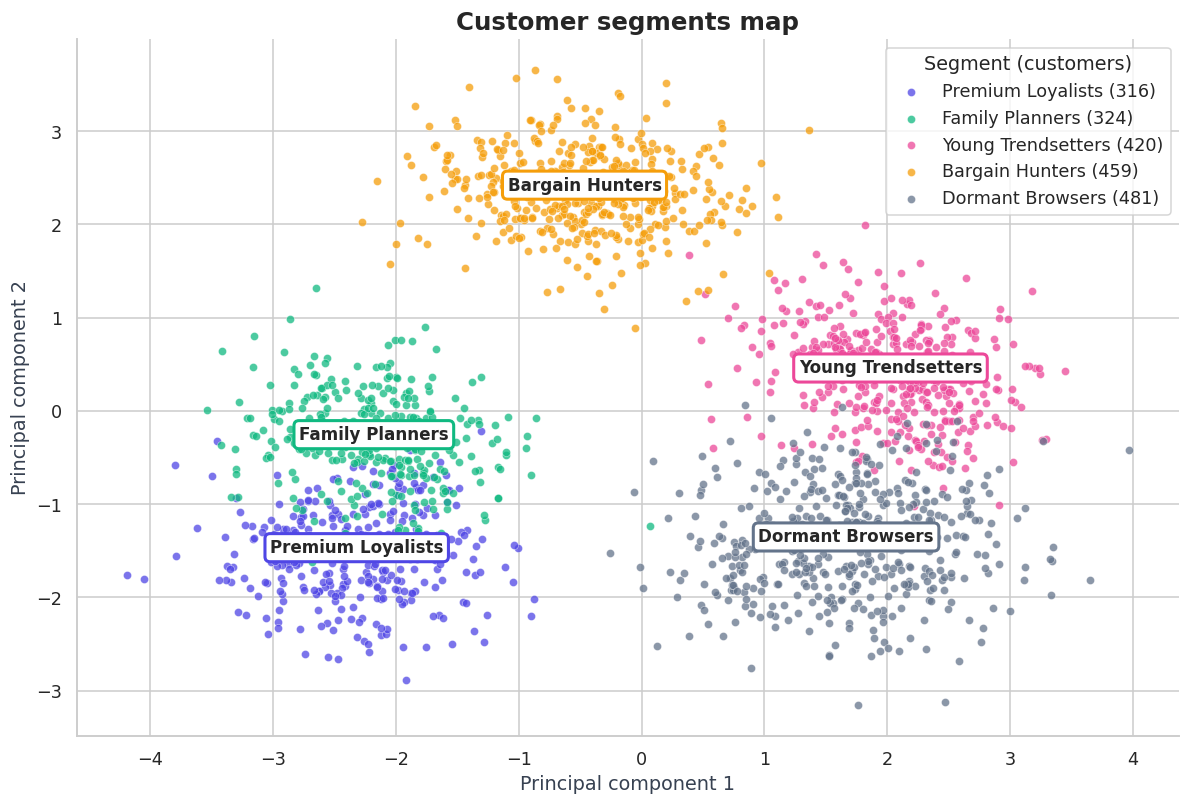

In [26]:
fig, ax = plt.subplots(figsize=(11, 7.5))
for seg in SEG_ORDER:
    d = df[df["Segment"] == seg]
    ax.scatter(d["PC1"], d["PC2"], s=28, alpha=.75, color=SEG_COLORS[seg], edgecolor="white", linewidth=.3, label=f"{seg} ({len(d):,})")
    ax.annotate(seg, (d["PC1"].mean(), d["PC2"].mean()), fontsize=11, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=SEG_COLORS[seg], lw=2))
ax.set_title("Customer segments map", fontsize=16); ax.set_xlabel("Principal component 1"); ax.set_ylabel("Principal component 2")
ax.legend(title="Segment (customers)", loc="best", frameon=True)
plt.tight_layout(); save_fig("13_segment_map"); plt.show()

> **Reading the map:** Premium Loyalists and Family Planners sit close together here because PCA keeps only about 55% of the information in two axes. They separate clearly on income, order value and household size (see the heatmap in 10.4), which is why the algorithm splits them.

### 10.3 Segment profile table
Average values per segment, with the colour intensity going from low to high across each row so differences stand out.

In [27]:
prof_cols = ["Age", "Annual_Income", "Tenure_Months", "Household_Size", "Recency_Days", "Frequency", "Avg_Order_Value",
             "Monetary", "Discount_Usage_Pct", "Online_Visits_Per_Month", "Cart_Abandon_Rate", "Return_Rate"]
profile = df.groupby("Segment", observed=True)[prof_cols].mean().T
profile.loc["Customers"]  = df["Segment"].value_counts()
profile.loc["% customers"] = (df["Segment"].value_counts(normalize=True) * 100)
profile.loc["% revenue"]   = df.groupby("Segment", observed=True)["Monetary"].sum() / df["Monetary"].sum() * 100
profile = profile[SEG_ORDER]

(profile.style.format("{:,.1f}").background_gradient(cmap="Blues", axis=1)
        .set_caption("Average customer profile by segment"))

Segment,Premium Loyalists,Family Planners,Young Trendsetters,Bargain Hunters,Dormant Browsers
Age,39.8,41.9,24.0,39.5,34.4
Annual_Income,"101,789.6","69,382.4","41,333.3","35,032.0","55,218.3"
Tenure_Months,59.4,55.0,20.2,41.9,31.4
Household_Size,1.9,5.0,1.5,3.0,2.5
Recency_Days,14.6,21.4,22.7,20.1,153.9
Frequency,25.9,18.0,20.3,30.0,4.0
Avg_Order_Value,142.9,94.2,48.2,29.8,54.8
Monetary,"3,693.1","1,684.4",974.2,891.3,218.6
Discount_Usage_Pct,14.0,38.9,59.0,85.3,34.1
Online_Visits_Per_Month,14.1,8.1,27.6,10.2,17.6


### 10.4 Which traits define each segment? (Index heatmap)
For `Recency_Days`, a high number means a *longer* time since the last purchase (worse). Each cell shows the segment average as a percentage of the **overall** average. 100 = same as all customers, 150 = 50% higher, 50 = half. This shows at a glance what makes each segment different.

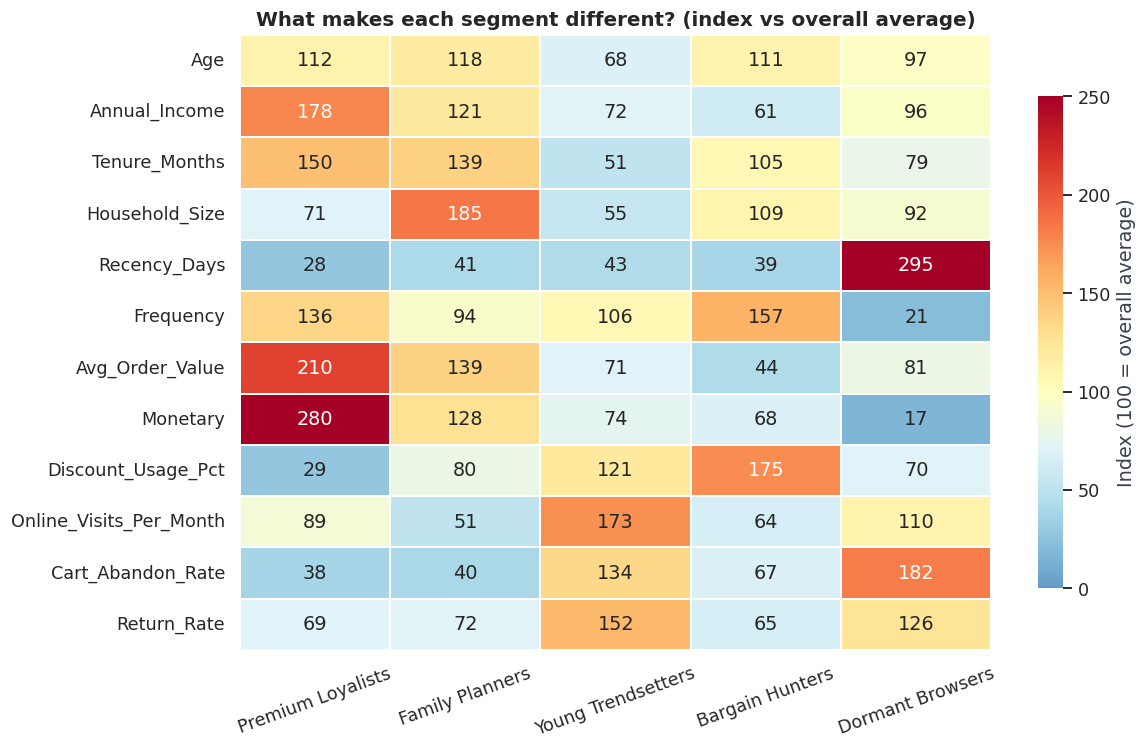

In [28]:
idx_tbl = (df.groupby("Segment", observed=True)[prof_cols].mean() / df[prof_cols].mean() * 100).T[SEG_ORDER]
plt.figure(figsize=(11, 7))
sns.heatmap(idx_tbl, annot=True, fmt=".0f", cmap="RdYlBu_r", center=100, vmin=0, vmax=250, linewidths=1, linecolor="white", cbar_kws={"label": "Index (100 = overall average)", "shrink": .8})
plt.title("What makes each segment different? (index vs overall average)"); plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=20)
plt.tight_layout(); save_fig("14_index_heatmap"); plt.show()

### 10.5 Segment fingerprints (radar chart)

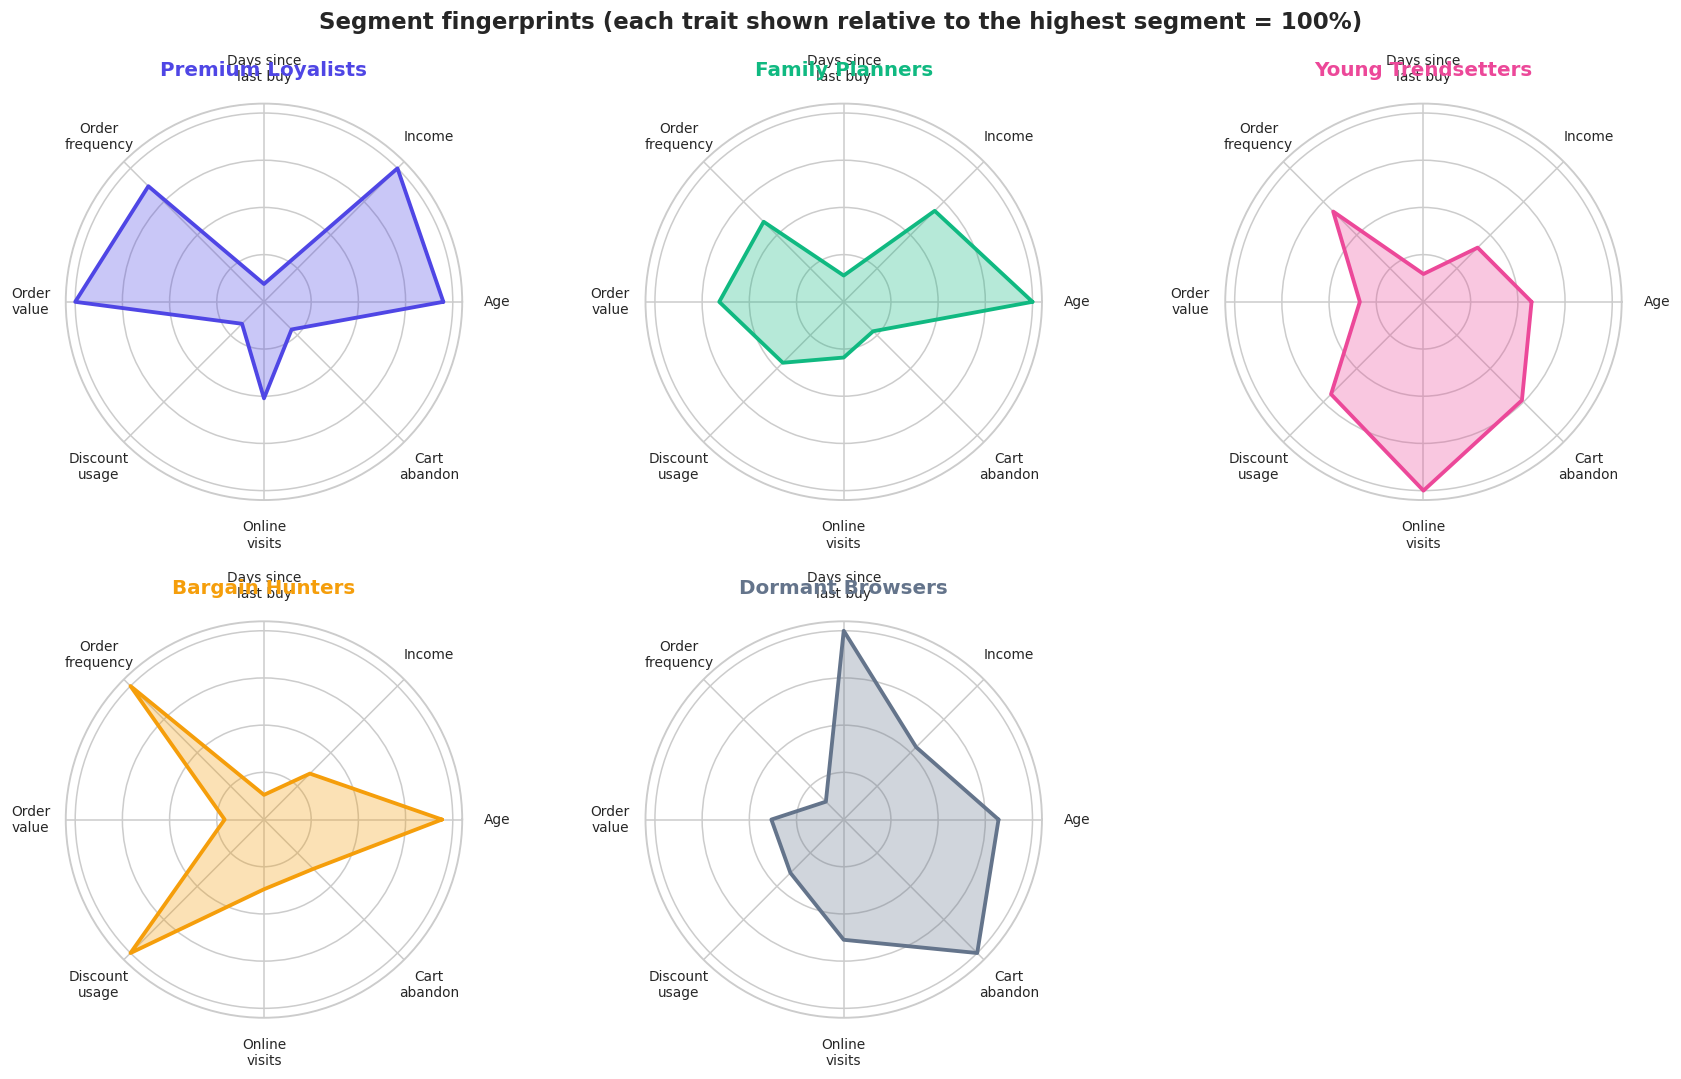

In [29]:
radar_feats = ["Age", "Annual_Income", "Recency_Days", "Frequency", "Avg_Order_Value", "Discount_Usage_Pct", "Online_Visits_Per_Month", "Cart_Abandon_Rate"]
means = df.groupby("Segment", observed=True)[radar_feats].mean().reindex(SEG_ORDER)
norm = means / means.max()                                                # 1.0 = the segment with the highest value on that trait
labels = {"Age": "Age", "Annual_Income": "Income", "Recency_Days": "Days since\nlast buy", "Frequency": "Order\nfrequency", "Avg_Order_Value": "Order\nvalue", "Discount_Usage_Pct": "Discount\nusage", "Online_Visits_Per_Month": "Online\nvisits", "Cart_Abandon_Rate": "Cart\nabandon"}
angles = np.linspace(0, 2 * np.pi, len(radar_feats), endpoint=False).tolist(); angles += angles[:1]

fig, axes = plt.subplots(2, 3, figsize=(16, 10), subplot_kw=dict(polar=True))
for ax, seg in zip(axes.ravel(), SEG_ORDER):
    vals = norm.loc[seg].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=SEG_COLORS[seg], lw=2.5); ax.fill(angles, vals, color=SEG_COLORS[seg], alpha=.3)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels([labels[f] for f in radar_feats], fontsize=9); ax.tick_params(axis="x", pad=10)
    ax.set_yticks([.25, .5, .75, 1]); ax.set_yticklabels([]); ax.set_ylim(0, 1.05); ax.set_title(seg, fontsize=13, fontweight="bold", color=SEG_COLORS[seg], pad=18)
axes.ravel()[-1].axis("off")
plt.suptitle("Segment fingerprints (each trait shown relative to the highest segment = 100%)", fontsize=15, fontweight="bold")
plt.tight_layout(); save_fig("15_radar"); plt.show()

### 10.6 Purchase patterns by segment

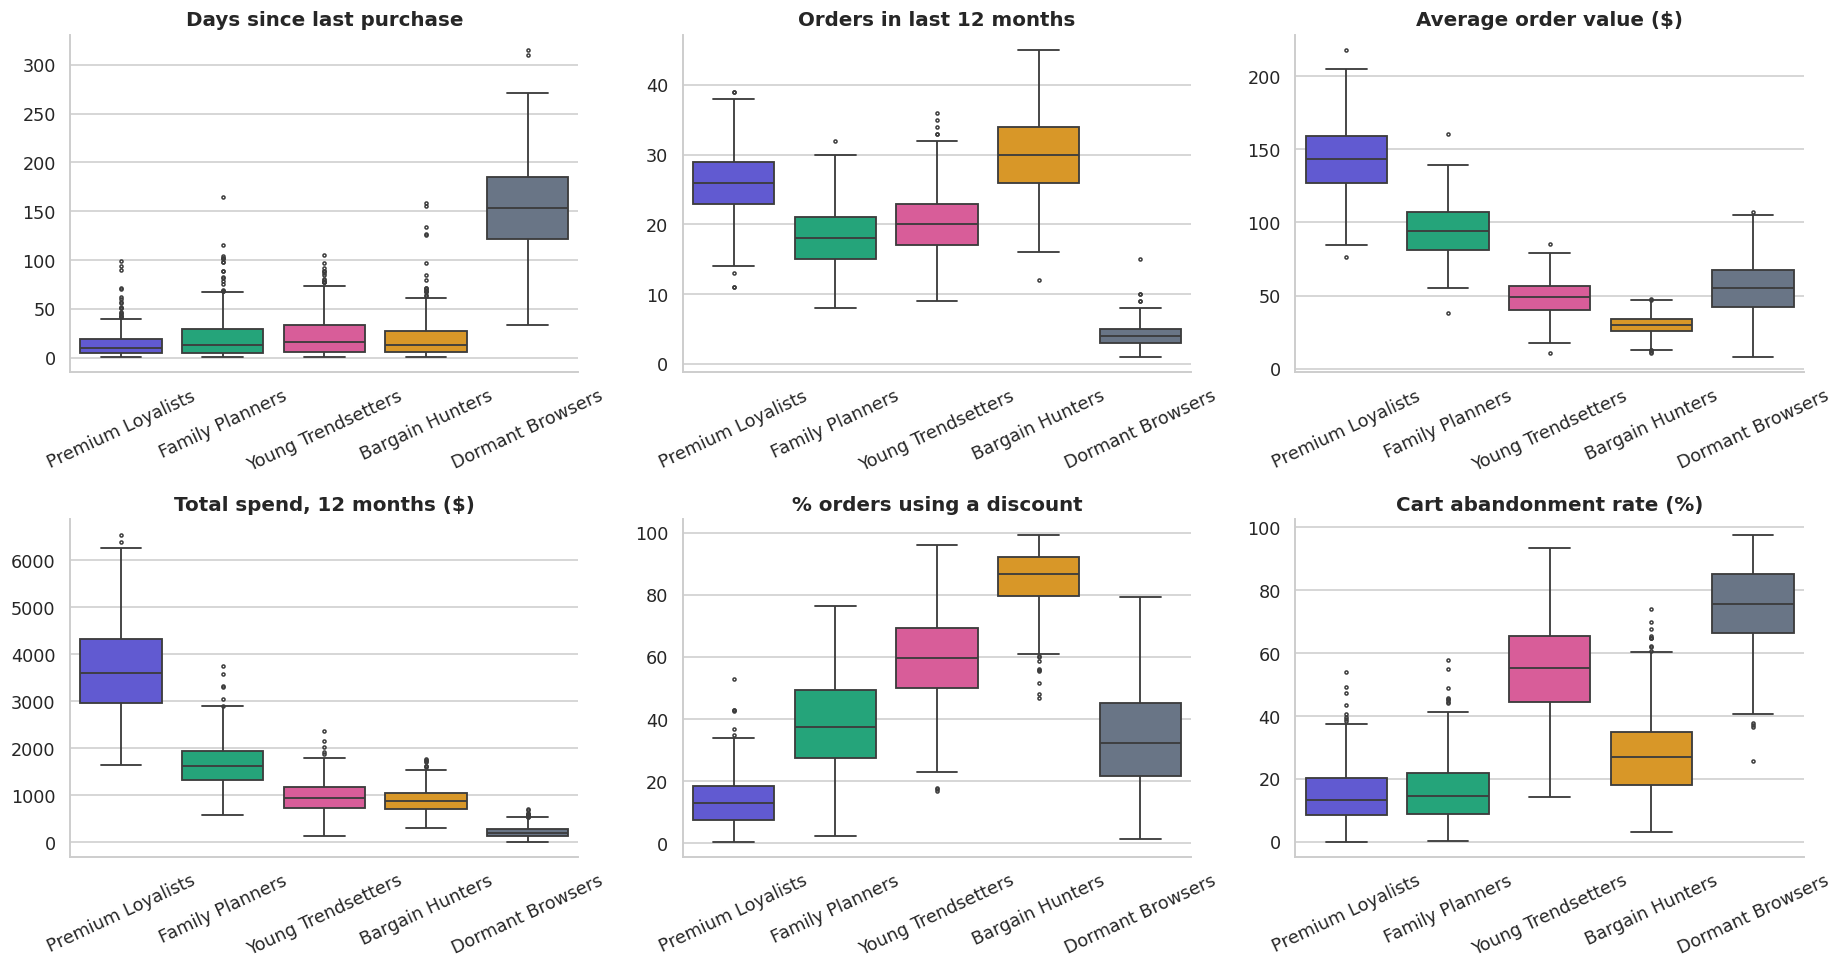

In [30]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
items = [("Recency_Days", "Days since last purchase"), ("Frequency", "Orders in last 12 months"), ("Avg_Order_Value", "Average order value ($)"),
         ("Monetary", "Total spend, 12 months ($)"), ("Discount_Usage_Pct", "% orders using a discount"), ("Cart_Abandon_Rate", "Cart abandonment rate (%)")]
for a, (col, title) in zip(ax.ravel(), items):
    sns.boxplot(data=df, x="Segment", y=col, hue="Segment", order=SEG_ORDER, hue_order=SEG_ORDER, palette=SEG_COLORS, legend=False, fliersize=2, linewidth=1.2, ax=a)
    a.set_title(title); a.set_xlabel(""); a.set_ylabel(""); a.tick_params(axis="x", rotation=25)
plt.tight_layout(); save_fig("16_purchase_patterns_by_segment"); plt.show()

### 10.7 Customer preferences by segment (category, channel, loyalty)

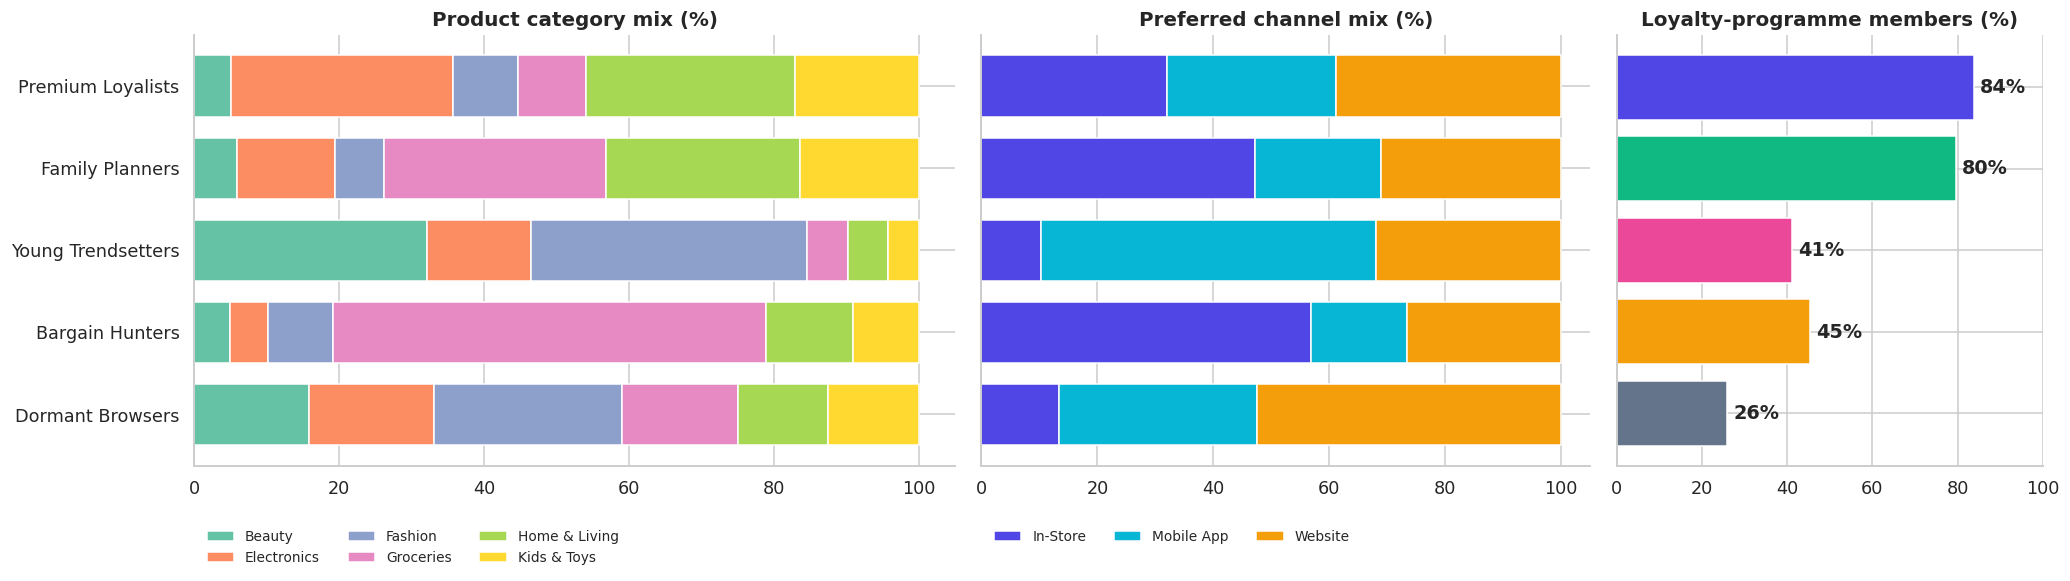

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.25, 1, .7]})

cat_mix = pd.crosstab(df["Segment"], df["Preferred_Category"], normalize="index").reindex(SEG_ORDER) * 100
cat_mix.plot.barh(stacked=True, ax=ax[0], color=sns.color_palette("Set2", 6), width=.75, edgecolor="white")
ax[0].set_title("Product category mix (%)"); ax[0].set_ylabel(""); ax[0].invert_yaxis(); ax[0].legend(bbox_to_anchor=(0, -.12), loc="upper left", ncol=3, frameon=False, fontsize=9)

ch_mix = pd.crosstab(df["Segment"], df["Preferred_Channel"], normalize="index").reindex(SEG_ORDER) * 100
ch_mix.plot.barh(stacked=True, ax=ax[1], color=["#4f46e5", "#06b6d4", "#f59e0b"], width=.75, edgecolor="white")
ax[1].set_title("Preferred channel mix (%)"); ax[1].set_ylabel(""); ax[1].set_yticklabels([]); ax[1].invert_yaxis(); ax[1].legend(bbox_to_anchor=(0, -.12), loc="upper left", ncol=3, frameon=False, fontsize=9)

loy = (df.assign(L=df["Loyalty_Member"].eq("Yes")).groupby("Segment", observed=True)["L"].mean().reindex(SEG_ORDER) * 100)
ax[2].barh(loy.index, loy.values, color=[SEG_COLORS[s] for s in loy.index]); ax[2].invert_yaxis()
ax[2].set_title("Loyalty-programme members (%)"); ax[2].set_yticklabels([]); ax[2].set_xlim(0, 100)
for i, v in enumerate(loy.values): ax[2].text(v + 1.5, i, f"{v:.0f}%", va="center", fontweight="bold")
plt.tight_layout(); save_fig("17_preferences_by_segment"); plt.show()

### 10.8 Demographics by segment

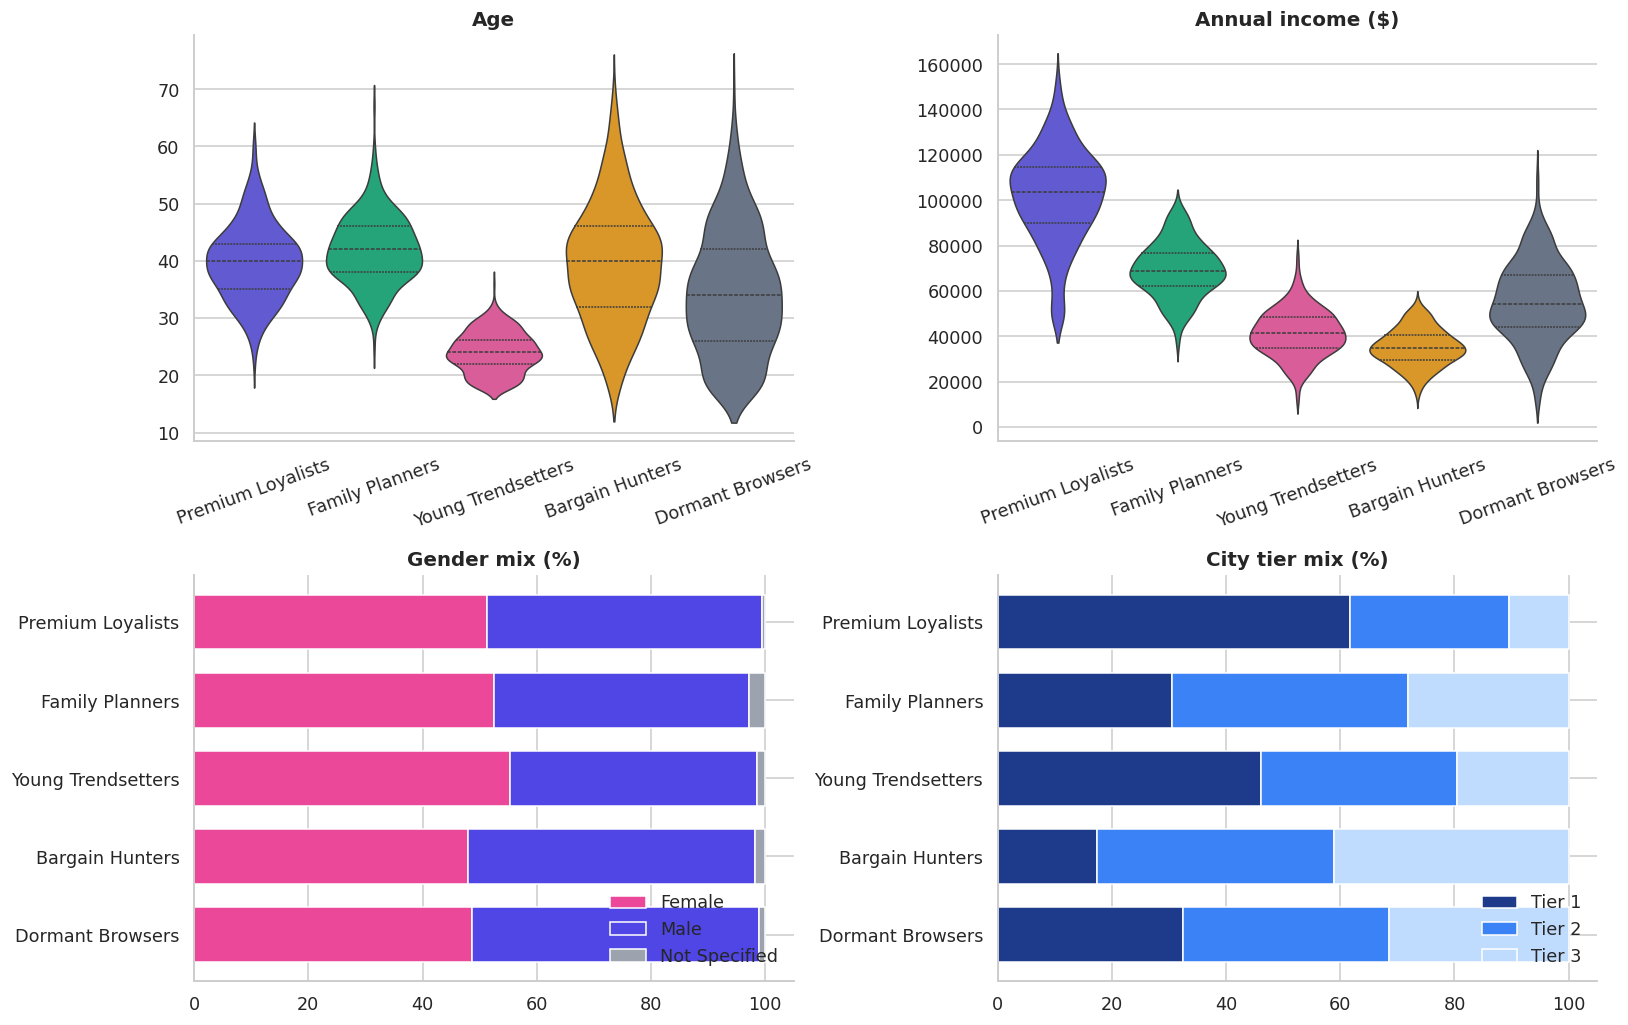

In [32]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9.5))
for a, (col, title) in zip(ax[0], [("Age", "Age"), ("Annual_Income", "Annual income ($)")]):
    sns.violinplot(data=df, x="Segment", y=col, hue="Segment", order=SEG_ORDER, hue_order=SEG_ORDER, palette=SEG_COLORS, legend=False, inner="quartile", linewidth=1, ax=a)
    a.set_title(title); a.set_xlabel(""); a.set_ylabel(""); a.tick_params(axis="x", rotation=20)

gmix = pd.crosstab(df["Segment"], df["Gender"], normalize="index").reindex(SEG_ORDER) * 100
gmix.plot.barh(stacked=True, ax=ax[1, 0], color=["#ec4899", "#4f46e5", "#9ca3af"][:gmix.shape[1]], width=.7, edgecolor="white")
ax[1, 0].set_title("Gender mix (%)"); ax[1, 0].set_ylabel(""); ax[1, 0].invert_yaxis(); ax[1, 0].legend(frameon=False, loc="lower right")

tmix = pd.crosstab(df["Segment"], df["City_Tier"], normalize="index").reindex(SEG_ORDER) * 100
tmix.plot.barh(stacked=True, ax=ax[1, 1], color=["#1e3a8a", "#3b82f6", "#bfdbfe"], width=.7, edgecolor="white")
ax[1, 1].set_title("City tier mix (%)"); ax[1, 1].set_ylabel(""); ax[1, 1].invert_yaxis(); ax[1, 1].legend(frameon=False, loc="lower right")
plt.tight_layout(); save_fig("18_demographics_by_segment"); plt.show()

### 10.9 Where does the money come from? (Value concentration)

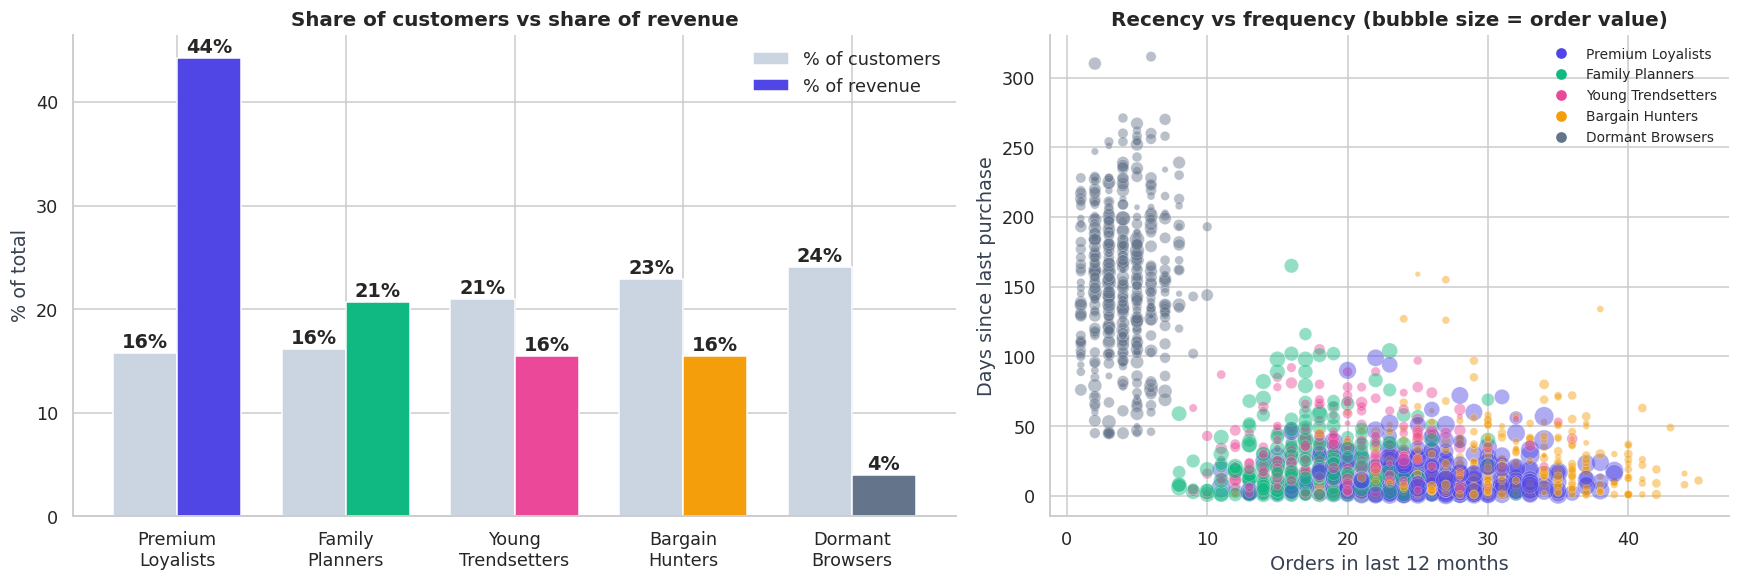

In [33]:
share = pd.DataFrame({"% of customers": df["Segment"].value_counts(normalize=True) * 100,
                      "% of revenue":   df.groupby("Segment", observed=True)["Monetary"].sum() / df["Monetary"].sum() * 100}).reindex(SEG_ORDER)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(share)); w = .38
b1 = ax[0].bar(x - w / 2, share["% of customers"], w, label="% of customers", color="#cbd5e1")
b2 = ax[0].bar(x + w / 2, share["% of revenue"], w, label="% of revenue", color=[SEG_COLORS[s] for s in share.index])
for b in list(b1) + list(b2): ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + .5, f"{b.get_height():.0f}%", ha="center", fontweight="bold")
ax[0].set_ylabel("% of total"); ax[0].set_xticks(x); ax[0].set_xticklabels([s.replace(" ", "\n") for s in share.index]); ax[0].set_title("Share of customers vs share of revenue"); ax[0].legend(frameon=False)

ax[1].scatter(df["Frequency"], df["Recency_Days"], c=df["Segment"].map(SEG_COLORS), s=df["Avg_Order_Value"] * .9, alpha=.45, edgecolor="white", linewidth=.3)
ax[1].set_xlabel("Orders in last 12 months"); ax[1].set_ylabel("Days since last purchase"); ax[1].set_title("Recency vs frequency (bubble size = order value)")
ax[1].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=s) for s, c in SEG_COLORS.items()], frameon=False, fontsize=9)
plt.tight_layout(); save_fig("19_value_concentration"); plt.show()

In [34]:
top = share["% of revenue"].idxmax()
print("Key insights from the profiling")
print("-" * 70)
for seg in SEG_ORDER:
    d = df[df["Segment"] == seg]
    print(f"- {seg:<20}: {len(d)/len(df)*100:4.1f}% of customers -> {share.loc[seg, '% of revenue']:4.1f}% of revenue | "
          f"top category: {d['Preferred_Category'].mode()[0]} | top channel: {d['Preferred_Channel'].mode()[0]}")
print(f"\n* The biggest revenue contributor is '{top}' ({share.loc[top, '% of revenue']:.0f}% of revenue from {share.loc[top, '% of customers']:.0f}% of customers).")
dorm = df[df["Segment"] == "Dormant Browsers"]
print(f"* 'Dormant Browsers' stay engaged online ({dorm['Online_Visits_Per_Month'].mean():.0f} visits/month vs {df['Online_Visits_Per_Month'].mean():.0f} overall) but abandon {dorm['Cart_Abandon_Rate'].mean():.0f}% of carts and last bought {dorm['Recency_Days'].mean():.0f} days ago -> interested, but not converting.")

Key insights from the profiling
----------------------------------------------------------------------
- Premium Loyalists   : 15.8% of customers -> 44.3% of revenue | top category: Electronics | top channel: Website
- Family Planners     : 16.2% of customers -> 20.7% of revenue | top category: Groceries | top channel: In-Store
- Young Trendsetters  : 21.0% of customers -> 15.5% of revenue | top category: Fashion | top channel: Mobile App
- Bargain Hunters     : 22.9% of customers -> 15.5% of revenue | top category: Groceries | top channel: In-Store
- Dormant Browsers    : 24.1% of customers ->  4.0% of revenue | top category: Fashion | top channel: Website

* The biggest revenue contributor is 'Premium Loyalists' (44% of revenue from 16% of customers).
* 'Dormant Browsers' stay engaged online (18 visits/month vs 16 overall) but abandon 75% of carts and last bought 154 days ago -> interested, but not converting.


# 11. Personas & Targeted Strategies
This turns the numbers into action. Each persona card is generated from the data above, and each strategy follows from that segment's measured behaviour.

In [35]:
STRAT = {
 "Premium Loyalists": dict(icon="👑", tag="High-value, frequent, full-price buyers",
    actions=["VIP tier: early access to launches, free express delivery, birthday gifts",
             "Premium bundles and personalised recommendations (their low discount usage suggests quality matters more than price)",
             "Avoid blanket discounts - they rarely use them and it would erode margin",
             "Ask for reviews and referrals: they are the best brand advocates"],
    kpi="Retention rate, customer lifetime value, referral count"),
 "Family Planners": dict(icon="🏡", tag="Large households, steady planned purchases",
    actions=["Household bundles and subscribe-and-save for groceries and home essentials",
             "Cross-sell Kids & Toys and Home & Living in the same basket",
             "Weekend and festive-season family offers; store pick-up and bulk delivery",
             "Loyalty points that grow with basket size"],
    kpi="Average basket value, repeat-purchase rate, subscription sign-ups"),
 "Young Trendsetters": dict(icon="✨", tag="Digital-first, trend and discount sensitive",
    actions=["App-first campaigns: push notifications, flash sales, new-arrival drops",
             "Social and influencer marketing; referral rewards and gamified points",
             "Easy returns and size guidance to bring down the high return rate",
             "Bundle offers to raise a small average order value"],
    kpi="App engagement, referral conversion, return rate, order value"),
 "Bargain Hunters": dict(icon="🏷️", tag="Very frequent, small baskets, deal-driven",
    actions=["Coupons and weekly deals on groceries - but protect margin",
             "Free-shipping or 'spend X, save Y' thresholds to lift basket size",
             "Private-label and multi-buy offers; points multipliers on non-sale items",
             "Track coupon ROI so discounts bring incremental orders"],
    kpi="Margin per order, average order value, coupon ROI"),
 "Dormant Browsers": dict(icon="😴", tag="Browse online, rarely buy, long silent",
    actions=["Win-back journey: time-limited personalised offer by email/push",
             "Cart-abandonment reminders and a simpler, faster checkout",
             "Short survey (price, delivery, trust?) to find the reason they do not convert",
             "Stop expensive acquisition-style spending on those who stay unresponsive"],
    kpi="Reactivation rate, cart-recovery rate, cost per reactivation"),
}

def persona_card(seg):
    d, s, col = df[df["Segment"] == seg], STRAT[seg], SEG_COLORS[seg]
    cat = d["Preferred_Category"].value_counts(normalize=True); ch = d["Preferred_Channel"].value_counts(normalize=True)
    cust_pct, rev_pct = len(d) / len(df) * 100, d["Monetary"].sum() / df["Monetary"].sum() * 100
    acts = "".join(f"<li style='margin:3px 0'>{a}</li>" for a in s["actions"])
    return (f"<div style='border-left:7px solid {col};background:#f8fafc;border-radius:10px;padding:16px 22px;margin:14px 0;"
            f"font-family:Segoe UI,Helvetica,Arial,sans-serif;color:#111827;box-shadow:0 1px 4px rgba(0,0,0,.12)'>"
            f"<div style='font-size:21px;font-weight:700;color:{col}'>{s['icon']} {seg}"
            f"<span style='font-size:13px;font-weight:500;color:#475569'> &nbsp;|&nbsp; {s['tag']}</span></div>"
            f"<div style='margin:10px 0 6px;font-size:14px;line-height:1.7;color:#1f2937'>"
            f"<b>Size:</b> {len(d):,} customers ({cust_pct:.0f}%) &nbsp;·&nbsp; <b>Revenue share:</b> {rev_pct:.0f}%<br>"
            f"<b>Who:</b> avg age {d['Age'].mean():.0f}, income ${d['Annual_Income'].mean():,.0f}, household of {d['Household_Size'].mean():.1f}<br>"
            f"<b>How they buy:</b> {d['Frequency'].mean():.0f} orders/year at ${d['Avg_Order_Value'].mean():,.0f} each, last purchase {d['Recency_Days'].mean():.0f} days ago, "
            f"{d['Discount_Usage_Pct'].mean():.0f}% of orders discounted, {d['Cart_Abandon_Rate'].mean():.0f}% carts abandoned<br>"
            f"<b>Prefers:</b> {cat.index[0]} ({cat.iloc[0]*100:.0f}%) and {cat.index[1]} ({cat.iloc[1]*100:.0f}%) &nbsp;·&nbsp; {ch.index[0]} ({ch.iloc[0]*100:.0f}%)</div>"
            f"<div style='font-weight:700;margin-top:8px;color:#111827'>Recommended actions</div><ul style='margin:4px 0 8px 18px;font-size:14px;color:#1f2937'>{acts}</ul>"
            f"<div style='font-size:13px;color:#334155'><b>KPIs to track:</b> {s['kpi']}</div></div>")

display(HTML("".join(persona_card(s) for s in SEG_ORDER)))

# 12. Business Impact (What-if Analysis)
To show the value of the segmentation, I estimate what a few targeted actions could add in revenue. **These are illustrative scenarios with assumptions I chose myself** (change them in the first lines of the cell). In real life they should be validated with A/B tests before committing budget.

,Extra annual revenue ($),% of current revenue
Dormant Browsers - win-back campaign,"$23,705",0.9%
Young Trendsetters - bundle offers,"$40,918",1.6%
Family Planners - subscribe & save,"$18,316",0.7%
TOTAL,"$82,939",3.1%


Current annual revenue of the customer base: $2,636,169


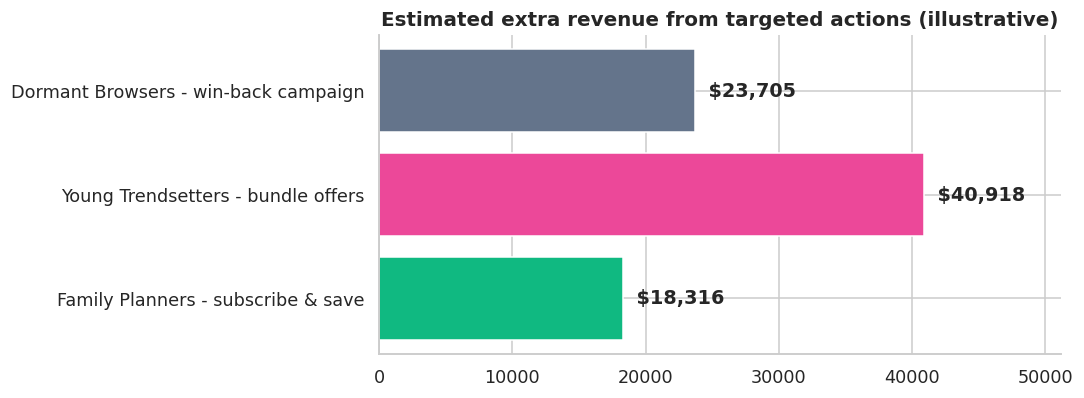

In [36]:
# ---- editable assumptions ----
A = dict(dormant_reactivation=0.15, dormant_extra_orders=6,      # win back 15% of Dormant Browsers, each buys 6 more times a year
         young_aov_uplift=0.10,                                   # bundles lift Young Trendsetters' order value by 10%
         family_adoption=0.30, family_extra_orders=2)             # 30% of Family Planners subscribe and place 2 extra orders a year

g = df.groupby("Segment", observed=True)
n, aov, rev = g.size(), g["Avg_Order_Value"].mean(), g["Monetary"].sum()

scen = pd.DataFrame({
    "Dormant Browsers - win-back campaign":     [A["dormant_reactivation"] * n["Dormant Browsers"] * A["dormant_extra_orders"] * aov["Dormant Browsers"]],
    "Young Trendsetters - bundle offers":       [A["young_aov_uplift"] * rev["Young Trendsetters"]],
    "Family Planners - subscribe & save":       [A["family_adoption"] * n["Family Planners"] * A["family_extra_orders"] * aov["Family Planners"]],
}).T.rename(columns={0: "Extra annual revenue ($)"})
scen["% of current revenue"] = scen["Extra annual revenue ($)"] / df["Monetary"].sum() * 100
scen.loc["TOTAL"] = [scen["Extra annual revenue ($)"].sum(), scen["% of current revenue"].sum()]

display(scen.style.format({"Extra annual revenue ($)": "${:,.0f}", "% of current revenue": "{:.1f}%"}))
print(f"Current annual revenue of the customer base: ${df['Monetary'].sum():,.0f}")

plot = scen.drop("TOTAL")
plt.figure(figsize=(10, 3.8))
plt.barh(plot.index, plot["Extra annual revenue ($)"], color=["#64748b", "#ec4899", "#10b981"])
for i, v in enumerate(plot["Extra annual revenue ($)"]): plt.text(v, i, f"  ${v:,.0f}", va="center", fontweight="bold")
plt.title("Estimated extra revenue from targeted actions (illustrative)"); plt.gca().invert_yaxis(); plt.xlim(0, plot["Extra annual revenue ($)"].max() * 1.25)
plt.tight_layout(); save_fig("20_what_if"); plt.show()

# 13. Exports & Power BI Dashboard Guide

### 13.1 Save the results
I export the labelled customer file (to share or load into Power BI), a one-page segment summary, and the trained model with a helper function so **new customers can be assigned to a segment automatically**.

In [37]:
import joblib

out_cols = ["CustomerID", "Segment", "Age", "Age_Group", "Gender", "City_Tier", "Annual_Income", "Income_Band", "Household_Size", "Tenure_Months",
            "Recency_Days", "Frequency", "Avg_Order_Value", "Monetary", "Monthly_Spend", "Discount_Usage_Pct", "Online_Visits_Per_Month",
            "Cart_Abandon_Rate", "Return_Rate", "Preferred_Category", "Preferred_Channel", "Loyalty_Member", "R_Score", "F_Score", "M_Score", "RFM_Total", "PC1", "PC2"]
df[out_cols].to_csv("customer_segments.csv", index=False)
profile.round(2).to_csv("segment_summary.csv")

joblib.dump({"scaler": scaler, "kmeans": kmeans, "features": FEATURES, "log_features": skewed, "cluster_names": names}, "segmentation_model.joblib")

def assign_segment(new_customers: pd.DataFrame) -> pd.Series:
    """Assign segment names to new customers (needs the 11 FEATURES columns, same cleaning applied)."""
    m = joblib.load("segmentation_model.joblib")
    Z = new_customers[m["features"]].copy()
    for c in m["log_features"]: Z[c] = np.log1p(Z[c])
    labels = m["kmeans"].predict(m["scaler"].transform(Z))
    return pd.Series(labels, index=new_customers.index).map(m["cluster_names"])

# sanity test: re-scoring existing customers must reproduce their segments exactly
test = df.sample(200, random_state=1)
assert (assign_segment(test).values == test["Segment"].astype(str).values).all()
print("Saved: customer_segments.csv, segment_summary.csv, segmentation_model.joblib, charts/*.png")
print("assign_segment() test passed - 200 customers re-scored with identical segments.")
display(assign_segment(df.head(5)).to_frame("Predicted segment").join(df[["CustomerID"]].head(5)))

Saved: customer_segments.csv, segment_summary.csv, segmentation_model.joblib, charts/*.png
assign_segment() test passed - 200 customers re-scored with identical segments.


,Predicted segment,CustomerID
0,Family Planners,CUST10000
1,Young Trendsetters,CUST10001
2,Dormant Browsers,CUST10002
3,Bargain Hunters,CUST10003
4,Dormant Browsers,CUST10004


### 13.2 Building the dashboard in Power BI
The project brief allows Python **or** Power BI, so I did the clustering in Python (more control and validation) and prepared the output for a Power BI dashboard.

**Steps**
1. **Get Data → Text/CSV →** `customer_segments.csv` → *Transform Data* → check that `Segment` is Text and the numeric columns are Decimal.
2. Create the DAX measures below.
3. Build 4 report pages (suggested layout below) and add slicers for **Segment, City_Tier, Age_Group, Preferred_Channel**.
4. Use **Segment** as the colour legend everywhere so a segment keeps the same colour on all pages.

```DAX
Total Customers  = DISTINCTCOUNT(customer_segments[CustomerID])
Total Revenue    = SUM(customer_segments[Monetary])
Revenue Share %  = DIVIDE([Total Revenue], CALCULATE([Total Revenue], ALL(customer_segments[Segment])))
Customer Share % = DIVIDE([Total Customers], CALCULATE([Total Customers], ALL(customer_segments[Segment])))
Avg Order Value  = DIVIDE([Total Revenue], SUM(customer_segments[Frequency]))
Avg Recency      = AVERAGE(customer_segments[Recency_Days])
```

| Page | Visuals |
|---|---|
| **1. Overview** | KPI cards (Total Customers, Total Revenue, Avg Order Value), donut of customers by Segment, bar of Revenue Share % by Segment |
| **2. Behaviour** | Matrix of segment averages (Recency, Frequency, AOV, Discount %), scatter Frequency vs Recency (legend = Segment) |
| **3. Preferences** | 100% stacked bars of Preferred_Category and Preferred_Channel by Segment |
| **4. Demographics** | Age_Group column chart, Income_Band, City_Tier, Gender by Segment |

> 💡 **Quick check in Power BI:** a scatter chart has a built-in *Analytics → Find clusters* option. I used it only as a cross-check on the Python result.

# 14. Executive Summary, Limitations & Next Steps

In [38]:
tot = df["Monetary"].sum()
p = df[df["Segment"] == "Premium Loyalists"]; d_ = df[df["Segment"] == "Dormant Browsers"]
summary_html = f"""
<div style="background:linear-gradient(120deg,#eef2ff,#ecfeff);border:1px solid #c7d2fe;border-radius:14px;padding:22px 26px;font-family:Segoe UI,Helvetica,Arial,sans-serif;color:#111827;line-height:1.7">
<div style="font-size:20px;font-weight:800;color:#3730a3;margin-bottom:8px">📊 Executive Summary</div>
<ul style="margin:0 0 0 18px;font-size:15px">
<li>I segmented <b>{len(df):,} customers</b> into <b>5 distinct groups</b> using K-Means on 11 behavioural and demographic features (silhouette = {sil:.2f}, stability ARI = {np.mean(aris):.3f}).</li>
<li><b>Premium Loyalists</b> are only <b>{len(p)/len(df)*100:.0f}%</b> of customers but generate <b>{p['Monetary'].sum()/tot*100:.0f}%</b> of revenue, so protecting this group is the top priority.</li>
<li><b>Dormant Browsers</b> are <b>{len(d_)/len(df)*100:.0f}%</b> of customers but only <b>{d_['Monetary'].sum()/tot*100:.0f}%</b> of revenue. They stay active online yet abandon {d_['Cart_Abandon_Rate'].mean():.0f}% of carts, a clear win-back opportunity.</li>
<li>Each segment has a different preferred category, channel and discount sensitivity, so a <b>single campaign for everyone would underperform</b>. Personalised strategies are given in Section 11.</li>
<li>Illustrative what-if estimate: three targeted actions could add about <b>${scen.loc['TOTAL', 'Extra annual revenue ($)']:,.0f}</b> (<b>{scen.loc['TOTAL', '% of current revenue']:.1f}%</b>) of annual revenue.</li>
</ul></div>"""
display(HTML(summary_html))

### ⚠️ Limitations (what I would be careful about)
- **Simulated data:** results show the *method* working end-to-end; with real company data, segment sizes and traits will differ and the number of clusters should be re-validated.
- **K-Means assumes roughly round, similar-sized clusters** and is sensitive to scaling and outliers. I reduced this with log transforms, scaling and cross-checks with two other algorithms.
- **Snapshot in time:** a single 12-month window cannot show how customers move between segments.
- **What-if numbers are assumptions**, not forecasts; they need A/B testing.
- Categorical preferences were used for *profiling*, not clustering. A method such as **K-Prototypes** could include them directly.

### 🚀 Next steps
1. Re-run the segmentation **every quarter** and track customers moving between segments (migration matrix).
2. Add **transaction-level data** (basket contents, seasonality) and compute **Customer Lifetime Value** per segment.
3. Run **A/B tests** on the strategies in Section 11, starting with the Dormant Browsers win-back.
4. Put the saved model (`segmentation_model.joblib`) behind a small API or a scheduled job so every new customer is segmented automatically.
5. Complete the Power BI dashboard and share it with the marketing team.

### 🧰 Tools used
`Python 3` · `pandas` · `NumPy` · `scikit-learn` (KMeans, Agglomerative, GaussianMixture, PCA, metrics) · `SciPy` · `Matplotlib` · `Seaborn` · `joblib` · `Power BI` (dashboard)

---
<div style="text-align:center;color:#64748b;font-size:13px">Prepared by <b> Anshika Sharma </b> · Ikkea · Customer Segmentation Internship Project</div>